# Report 1: Fuzzy C-Means on KC1 (NASA software defect data)

## Step 1: Load the raw data and sanity checks

Source: `data/code_analysis/kc1.arff`, PROMISE repository version of KC1 (NASA Metrics Data Program, donated by
Tim Menzies, 2 Dec 2004; see the `%` comment block of the file). ARFF = Weka's format: `@attribute` lines declare the
columns, the rows after `@data` are comma-separated.
One row = one module (function/method) of a C++ system; 21 static code metrics (McCabe, Halstead, line counts)
and the label `defects` (the module has >= 1 reported defect). Expected values below are from the file header.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.io import arff

# Paths are relative to this notebook (Reports/Report 1/src/code_analysis/)
REPORT_DIR = Path("../..")
DATA_DIR = REPORT_DIR / "data" / "code_analysis"
OUT_DIR = REPORT_DIR / "data" / "code_analysis"
OUT_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
raw, meta = arff.loadarff(DATA_DIR / "kc1.arff")
df = pd.DataFrame(raw)
df["defects"] = df["defects"].str.decode("utf-8").map({"false": False, "true": True})   # scipy returns bytes
FEATURES = [c for c in df.columns if c != "defects"]

# Sanity checks (expected values from the kc1.arff header)
print("shape:", df.shape)                                            # expect (2109, 22)
print("all features numeric:", all(pd.api.types.is_float_dtype(df[c]) for c in FEATURES))
print("missing values:", df.isna().sum().sum())                      # expect 0
print("defects:", df["defects"].value_counts().to_dict(),
      f"({df['defects'].mean():.2%} defective)")                     # expect True 326, False 1783
print("duplicate rows (features + label):", df.duplicated().sum())
print("duplicate feature rows:", df.duplicated(subset=FEATURES).sum())

df.to_csv(OUT_DIR / "kc1_raw.csv", index=False)
print("saved:", (OUT_DIR / "kc1_raw.csv").resolve())
df.head(3)

shape: (2109, 22)
all features numeric: True
missing values: 0
defects: {False: 1783, True: 326} (15.46% defective)
duplicate rows (features + label): 897
duplicate feature rows: 917
saved: /home/stefy/Work/University/Master/Anul I/Metode Avansate de Analiza a Datelor/Reports/Report 1/data/code_analysis/kc1_raw.csv


,loc,v(g),ev(g),iv(g),n,v,l,d,i,e,...,lOCode,lOComment,lOBlank,locCodeAndComment,uniq_Op,uniq_Opnd,total_Op,total_Opnd,branchCount,defects
0,1.1,1.4,1.4,1.4,1.3,1.30,1.30,1.30,1.30,1.30,...,2.0,2.0,2.0,2.0,1.2,1.2,1.2,1.2,1.4,False
1,1.0,1.0,1.0,1.0,1.0,1.00,1.00,1.00,1.00,1.00,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,True
2,83.0,11.0,1.0,11.0,171.0,927.89,0.04,23.04,40.27,21378.61,...,65.0,10.0,6.0,0.0,18.0,25.0,107.0,64.0,21.0,True


## Step 2: Data-quality checks (Shepperd et al. 2013)

Reference: Shepperd, Song, Sun & Mair (2013), *Data Quality: Some Comments on the NASA Software Defect Datasets*,
IEEE TSE 39(9), 1208-1215: Appendix (implausible values, referential integrity checks), Fig. 1 (cleaning procedure),
Table 4 (counts for KC1, Promise version). **Nothing is removed in this step**: we only count.

The paper uses the MDP column names. The mapping to the PROMISE names below is **our inference** from the
descriptions in the `.arff` header; 2d compares our counts with Table 4 to check it.

- 2a: implausible values
- 2b: referential integrity checks
- 2c: identical and inconsistent cases
- 2d: our counts vs the paper

In [4]:
# PROMISE name -> MDP name used in Shepperd et al. (2013), Appendix (our inference)
MDP_NAME = {
    "loc": "LOC_TOTAL", "v(g)": "CYCLOMATIC_COMPLEXITY", "ev(g)": "ESSENTIAL_COMPLEXITY",
    "iv(g)": "DESIGN_COMPLEXITY", "n": "HALSTEAD_LENGTH", "v": "HALSTEAD_VOLUME", "l": "HALSTEAD_LEVEL",
    "d": "HALSTEAD_DIFFICULTY", "i": "HALSTEAD_CONTENT", "e": "HALSTEAD_EFFORT", "b": "HALSTEAD_ERROR_EST",
    "t": "HALSTEAD_PROG_TIME", "lOCode": "LOC_EXECUTABLE", "lOComment": "LOC_COMMENTS", "lOBlank": "LOC_BLANK",
    "locCodeAndComment": "LOC_CODE_AND_COMMENT", "uniq_Op": "NUM_UNIQUE_OPERATORS",
    "uniq_Opnd": "NUM_UNIQUE_OPERANDS", "total_Op": "NUM_OPERATORS", "total_Opnd": "NUM_OPERANDS",
    "branchCount": "BRANCH_COUNT",
}
# Features that are counts (must be whole numbers); the Halstead derived measures v, l, d, i, e, b, t are not
COUNTS = ["loc", "v(g)", "ev(g)", "iv(g)", "n", "lOCode", "lOComment", "lOBlank", "locCodeAndComment",
          "uniq_Op", "uniq_Opnd", "total_Op", "total_Opnd", "branchCount"]

### 2a: Implausible values (Shepperd et al. 2013, Appendix)

Three rules: `LOC_TOTAL = 0`; any value `< 0`; any count that is not a whole number.

In [5]:
nonint = df[COUNTS].ne(df[COUNTS].round())
implaus_feat = pd.DataFrame({
    "MDP name": [MDP_NAME[c] for c in FEATURES],
    "< 0": [(df[c] < 0).sum() for c in FEATURES],
    "non-integer count": [nonint[c].sum() if c in COUNTS else np.nan for c in FEATURES],
}, index=FEATURES)
implaus_feat.loc["loc", "== 0"] = (df["loc"] == 0).sum()

implaus_row = pd.DataFrame({
    "loc == 0": df["loc"] == 0,
    "any < 0": (df[FEATURES] < 0).any(axis=1),
    "non-integer count": nonint.any(axis=1),
})
implaus_row["implausible"] = implaus_row.any(axis=1)
print("rows per rule:", implaus_row.sum().to_dict())
print("features with >= 1 implausible value:",
      int((implaus_feat[["< 0", "non-integer count", "== 0"]].fillna(0).sum(axis=1) > 0).sum()))
implaus_feat.to_csv(OUT_DIR / "kc1_implausible_by_feature.csv", index_label="feature")
df[implaus_row["implausible"]]

rows per rule: {'loc == 0': 0, 'any < 0': 0, 'non-integer count': 1, 'implausible': 1}
features with >= 1 implausible value: 10


,loc,v(g),ev(g),iv(g),n,v,l,d,i,e,...,lOCode,lOComment,lOBlank,locCodeAndComment,uniq_Op,uniq_Opnd,total_Op,total_Opnd,branchCount,defects
0,1.1,1.4,1.4,1.4,1.3,1.3,1.3,1.3,1.3,1.3,...,2.0,2.0,2.0,2.0,1.2,1.2,1.2,1.2,1.4,False


### 2b: Referential integrity checks (Shepperd et al. 2013, Appendix)

Rules 1-5 (`NUMBER_OF_LINES`) and 12 (`CALL_PAIRS`) cannot be checked: these columns are not in the PROMISE file.
Rules 6-11 compare counts and are checked exactly. Rules 13-18 are Halstead formulas; the stored values are rounded
to 2 decimals and the paper does not say which tolerance was used, so the number of violations is shown for several
relative tolerances (always allowing an absolute error of 0.005 from rounding).
A formula that cannot be computed (division by 0) is counted separately, not as a violation.

In [6]:
N1, N2, n1, n2 = df["total_Op"], df["total_Opnd"], df["uniq_Op"], df["uniq_Opnd"]

# Rules 6-11: inequalities / equalities between counts (True = rule holds)
INEQ = {
    "6  loc >= lOCode":                 df["loc"] >= df["lOCode"],
    "7  loc >= locCodeAndComment":      df["loc"] >= df["locCodeAndComment"],
    "8  total_Opnd >= uniq_Opnd":       N2 >= n2,
    "9  total_Op >= uniq_Op":           N1 >= n1,
    "10 n == total_Op + total_Opnd":    df["n"] == N1 + N2,
    "11 v(g) <= total_Op + 1":          df["v(g)"] <= N1 + 1,
}

# Rules 13-18: Halstead formulas (stored column, value computed from the formula)
with np.errstate(divide="ignore", invalid="ignore"):
    FORMULA = {
        "13 v == (N1+N2) log2(n1+n2)": ("v", (N1 + N2) * np.log2(n1 + n2)),
        "14 l == (2/n1)(n2/N2)":       ("l", (2 / n1) * (n2 / N2)),
        "15 d == (n1/2)(N2/n2)":       ("d", (n1 / 2) * (N2 / n2)),
        "16 i == v / d":               ("i", df["v"] / df["d"]),
        "17 e == v * d":               ("e", df["v"] * df["d"]),
        "18 t == e / 18":              ("t", df["e"] / 18),
    }

RTOLS = [0.0, 0.001, 0.01, 0.05]
ok = {}            # rule -> {rtol: boolean Series}, True = rule holds
rows = []
for name, holds in INEQ.items():
    rows.append({"rule": name, "not computable": 0, **{f"viol rtol={r}": int((~holds).sum()) for r in RTOLS}})
    ok[name] = {r: holds for r in RTOLS}
for name, (col, calc) in FORMULA.items():
    calc = calc.replace([np.inf, -np.inf], np.nan)
    computable = calc.notna()
    ok[name] = {}
    row = {"rule": name, "not computable": int((~computable).sum())}
    for r in RTOLS:
        holds = ~computable | np.isclose(df[col], calc, rtol=r, atol=0.005)
        ok[name][r] = holds
        row[f"viol rtol={r}"] = int((~holds).sum())
    rows.append(row)
integrity = pd.DataFrame(rows).set_index("rule")
integrity.to_csv(OUT_DIR / "kc1_integrity_checks.csv")

conflict_rows = pd.DataFrame({r: pd.concat([~ok[k][r] for k in ok], axis=1).any(axis=1) for r in RTOLS})
print("rows violating >= 1 rule, by tolerance:", conflict_rows.sum().to_dict())
integrity

rows violating >= 1 rule, by tolerance: {0.0: 1121, 0.001: 45, 0.01: 13, 0.05: 13}


,not computable,viol rtol=0.0,viol rtol=0.001,viol rtol=0.01,viol rtol=0.05
rule,,,,,
6 loc >= lOCode,0,1,1,1,1
7 loc >= locCodeAndComment,0,1,1,1,1
8 total_Opnd >= uniq_Opnd,0,0,0,0,0
9 total_Op >= uniq_Op,0,0,0,0,0
10 n == total_Op + total_Opnd,0,2,2,2,2
11 v(g) <= total_Op + 1,0,11,11,11,11
13 v == (N1+N2) log2(n1+n2),55,7,2,2,2
14 l == (2/n1)(n2/N2),167,17,2,2,2
15 d == (n1/2)(N2/n2),163,19,2,2,2


### 2c: Identical and inconsistent cases (Shepperd et al. 2013, Fig. 1, steps 3-4)

* identical: same values on all features **and** the label (Fig. 1 keeps the first and removes the others);
* inconsistent: same values on all features but a **different** label (Fig. 1 removes both).

Table 4 does not say whether "inconsistent cases" counts rows or pairs, nor whether it is counted before or after
removing identical cases, so several counts are shown.

In [7]:
dup_extra = df.duplicated(keep="first")                     # rows Fig. 1 step 3 would remove
grp = df.groupby(FEATURES, sort=False)["defects"]
n_labels = grp.transform("nunique")                         # 2 = feature vector appears with both labels

dedup = df[~dup_extra]
n_labels_dedup = dedup.groupby(FEATURES, sort=False)["defects"].transform("nunique")

print("identical (extra copies removed by step 3):", int(dup_extra.sum()))
print("rows that have >= 1 identical copy (incl. the first):", int(df.duplicated(keep=False).sum()))
print("distinct feature vectors with both labels:", int((grp.nunique() == 2).sum()))
print("raw rows in such groups:", int((n_labels == 2).sum()))
print("rows in such groups after removing identical:", int((n_labels_dedup == 2).sum()))

# Most repeated feature vectors
top = (df.groupby(FEATURES, sort=False)["defects"].agg(rows="size", defective="sum")
       .sort_values("rows", ascending=False).head(10).reset_index())
top

identical (extra copies removed by step 3): 897
rows that have >= 1 identical copy (incl. the first): 1070
distinct feature vectors with both labels: 20
raw rows in such groups: 253
rows in such groups after removing identical: 40


,loc,v(g),ev(g),iv(g),n,v,l,d,i,e,...,lOComment,lOBlank,locCodeAndComment,uniq_Op,uniq_Opnd,total_Op,total_Opnd,branchCount,rows,defective
0,2.0,1.0,1.0,1.0,4.0,8.00,0.67,1.5,5.33,12.00,...,0.0,0.0,0.0,3.0,1.0,3.0,1.0,1.0,112,0
1,1.0,1.0,1.0,1.0,4.0,8.00,0.67,1.5,5.33,12.00,...,0.0,0.0,0.0,3.0,1.0,3.0,1.0,1.0,104,0
2,3.0,1.0,1.0,1.0,1.0,0.00,0.00,0.0,0.00,0.00,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,73,2
3,4.0,1.0,1.0,1.0,4.0,8.00,0.67,1.5,5.33,12.00,...,0.0,0.0,0.0,3.0,1.0,3.0,1.0,1.0,59,4
4,2.0,1.0,1.0,1.0,5.0,11.61,0.67,1.5,7.74,17.41,...,0.0,0.0,0.0,3.0,2.0,3.0,2.0,1.0,50,0
5,4.0,1.0,1.0,1.0,4.0,8.00,0.67,1.5,5.33,12.00,...,0.0,0.0,0.0,3.0,1.0,3.0,1.0,1.0,31,0
6,2.0,1.0,1.0,1.0,3.0,4.75,1.00,1.0,4.75,4.75,...,0.0,0.0,0.0,2.0,1.0,2.0,1.0,1.0,22,1
7,4.0,1.0,1.0,1.0,3.0,4.75,1.00,1.0,4.75,4.75,...,0.0,0.0,0.0,2.0,1.0,2.0,1.0,1.0,20,0
8,4.0,1.0,1.0,1.0,5.0,11.61,0.50,2.0,5.80,23.22,...,0.0,0.0,0.0,4.0,1.0,4.0,1.0,1.0,20,1
9,4.0,1.0,1.0,1.0,7.0,19.65,0.40,2.5,7.86,49.13,...,0.0,0.0,0.0,5.0,2.0,5.0,2.0,1.0,17,0


### 2d: Our counts vs Shepperd et al. (2013), Table 4 (KC1, Promise)

In [8]:
CHOSEN_RTOL = 0.01      # only for this summary; the table in 2b shows all tolerances
compare = pd.DataFrame({
    "paper (Table 4, Promise)": {
        "identical cases": 1070, "inconsistent cases": 253, "cases with missing values": 0,
        "cases with conflicting feature values": 14, "cases with implausible values": 1,
        "total problem cases DS'": 14, "total problem cases DS''": 947},
    "ours": {
        "identical cases": int(df.duplicated(keep=False).sum()),      # rows with >= 1 identical copy, incl. the first
        "inconsistent cases": int((n_labels == 2).sum()),             # raw rows whose feature vector has both labels
        "cases with missing values": int(df.isna().any(axis=1).sum()),
        "cases with conflicting feature values": int(conflict_rows[CHOSEN_RTOL].sum()),
        "cases with implausible values": int(implaus_row["implausible"].sum()),
        "total problem cases DS'": int((conflict_rows[CHOSEN_RTOL] | implaus_row["implausible"]).sum()),
        "total problem cases DS''": np.nan},   # depends on the order of the steps; computed when we clean
})
compare.to_csv(OUT_DIR / "kc1_quality_vs_shepperd.csv", index_label="check")
compare

,"paper (Table 4, Promise)",ours
identical cases,1070,1070.0
inconsistent cases,253,253.0
cases with missing values,0,0.0
cases with conflicting feature values,14,13.0
cases with implausible values,1,1.0
total problem cases DS',14,13.0
total problem cases DS'',947,NaN


## Step 3: Cleaning: DS' and DS'' (Shepperd et al. 2013, Fig. 1)

Decision (Stefan, 18 Nov): build **both** versions and cluster both; DS' is the main analysis, DS'' the comparison.

- **DS'**: Fig. 1 steps 1-2 (and 5-7): remove cases with implausible values (2a) and cases that violate an integrity
  rule (2b, at `CHOSEN_RTOL`). Identical cases are kept: they are different modules with the same metrics
  (Shepperd et al. 2013, Sec. 2).
- **DS''**: additionally Fig. 1 step 3 (identical cases: keep the first, remove the others) and step 4 (inconsistent
  cases: same features, different label: remove both), in this order (the paper notes the order matters).
- Steps 5-7 (missing values, constant features, identical features) are applied to both.

Paper (Table 4, KC1 Promise): 14 problem cases for DS', 947 for DS'' (so 2095 and 1162 cases left).
For FCM the label is not used, but identical cases act as weights: a point repeated 112 times pulls a prototype
112 times as hard as a single point.

In [9]:
def clean_steps_5_7(d):
    """Fig. 1 steps 5-7: drop cases with missing values, constant features, identical features."""
    d = d.dropna()
    feats = [c for c in d.columns if c != "defects"]
    constant = [c for c in feats if d[c].nunique() == 1]
    identical = [b for i, a in enumerate(feats) for b in feats[i + 1:] if d[a].equals(d[b])]
    return d.drop(columns=sorted(set(constant) | set(identical))), constant, identical

steps = [("raw", len(df))]
bad = implaus_row["implausible"] | conflict_rows[CHOSEN_RTOL]        # steps 1-2
ds1 = df[~bad]
steps.append(("after steps 1-2 (implausible, conflicting)", len(ds1)))

ds2 = ds1[~ds1.duplicated(keep="first")]                              # step 3
steps.append(("after step 3 (identical)", len(ds2)))
both = ds2.groupby(FEATURES, sort=False)["defects"].transform("nunique") == 2
ds2 = ds2[~both]                                                      # step 4: remove both cases of each pair
steps.append(("after step 4 (inconsistent)", len(ds2)))

DS = {}
for name, d in [("DS1", ds1), ("DS2", ds2)]:
    DS[name], const, ident = clean_steps_5_7(d)
    print(f"{name}: constant features {const}, identical features {ident}, shape {DS[name].shape}")
steps = pd.DataFrame(steps, columns=["stage", "cases"]).set_index("stage")
print("paper: DS' 2095 cases, DS'' 1162 cases")

summary = pd.DataFrame({
    name: {"cases": len(d), "removed": len(df) - len(d), "defective": int(d["defects"].sum()),
           "defective share": round(d["defects"].mean(), 4),
           "distinct feature vectors": len(d.drop(columns="defects").drop_duplicates())}
    for name, d in DS.items()}).T
for name, d in DS.items():
    d.to_csv(OUT_DIR / f"kc1_{name.lower()}.csv", index=False)
summary.to_csv(OUT_DIR / "kc1_cleaning_summary.csv", index_label="version")
display(steps, summary)

DS1: constant features [], identical features [], shape (2096, 22)
DS2: constant features [], identical features [], shape (1163, 22)
paper: DS' 2095 cases, DS'' 1162 cases


,cases
stage,
raw,2109
"after steps 1-2 (implausible, conflicting)",2096
after step 3 (identical),1203
after step 4 (inconsistent),1163


,cases,removed,defective,defective share,distinct feature vectors
DS1,2096.0,13.0,325.0,0.1551,1183.0
DS2,1163.0,946.0,294.0,0.2528,1163.0


## Step 4: Exploratory look at the features

Goal: measure the properties of the 21 metrics in both cleaned versions (DS1 = DS', main; DS2 = DS'', comparison)
before choosing features, transformation and scaling. Nothing is decided here; the outputs are evidence for Step 5.
The label `defects` is not used, except to describe the most repeated vectors in 4f.

- 4a: summary statistics (ranges, scales, share of zeros)
- 4b: skewness, raw and after log1p (log10 is not possible: many metrics contain 0)
- 4c: correlation matrices (Pearson and Spearman)
- 4d: feature distributions
- 4e: PCA explained variance
- 4f: weight of the repeated feature vectors in DS1

In [17]:
import matplotlib.pyplot as plt

FIG_DIR = REPORT_DIR / "figures" / "code_analysis"
FIG_DIR.mkdir(parents=True, exist_ok=True)

XS = {name: d[FEATURES] for name, d in DS.items()}      # features only, per cleaned version

### 4a: Summary statistics

In [18]:
summaries = {}
for name, X in XS.items():
    s = X.describe().T
    s["share_zero"] = (X == 0).mean()
    s.to_csv(OUT_DIR / f"kc1_{name.lower()}_summary.csv")
    summaries[name] = s
    print(f"{name}: largest/smallest std = {s['std'].max() / s['std'].min():.3g}"
          f" ({s['std'].idxmax()} / {s['std'].idxmin()});"
          f" features containing 0: {(s['share_zero'] > 0).sum()} of {len(s)}")
summaries["DS1"]

DS1: largest/smallest std = 1.01e+05 (e / b); features containing 0: 16 of 21
DS2: largest/smallest std = 1.07e+05 (e / b); features containing 0: 16 of 21


,count,mean,std,min,25%,50%,75%,max,share_zero
loc,2096.0,20.370229,29.832841,1.0,3.00,9.00,24.000,288.00,0.000000
v(g),2096.0,2.843034,3.912123,1.0,1.00,1.00,3.000,45.00,0.000000
ev(g),2096.0,1.678435,2.206874,1.0,1.00,1.00,1.000,26.00,0.000000
iv(g),2096.0,2.549618,3.385836,1.0,1.00,1.00,3.000,45.00,0.000000
n,2096.0,50.137405,83.767015,0.0,4.00,17.00,58.000,1106.00,0.020992
v,2096.0,260.300134,517.514061,0.0,8.00,58.81,270.510,7918.82,0.070134
l,2096.0,0.320468,0.316092,0.0,0.08,0.20,0.670,2.00,0.074427
d,2096.0,6.812142,7.870707,0.0,1.50,3.50,9.315,53.75,0.074427
i,2096.0,21.370711,21.502630,0.0,5.33,14.45,29.880,193.06,0.074427
e,2096.0,5274.899943,17494.119424,0.0,12.00,220.91,2287.655,324803.51,0.074427


### 4b: Skewness, raw and after log1p

log1p(x) = log(1 + x) is defined at 0 and is close to log(x) for large x.
Common rule of thumb: |skew| < 0.5 roughly symmetric, 0.5-1 moderate, > 1 strong.

In [19]:
skew = pd.DataFrame({f"{name} {kind}": (X if kind == "raw" else np.log1p(X)).skew()
                     for name, X in XS.items() for kind in ("raw", "log1p")})
skew = skew.sort_values("DS1 raw", ascending=False)
skew.to_csv(OUT_DIR / "kc1_skewness.csv", index_label="feature")
for col in skew.columns:
    print(f"{col}: features with |skew| > 1: {(skew[col].abs() > 1).sum()} of {len(skew)}")
skew

DS1 raw: features with |skew| > 1: 21 of 21
DS1 log1p: features with |skew| > 1: 8 of 21
DS2 raw: features with |skew| > 1: 20 of 21
DS2 log1p: features with |skew| > 1: 7 of 21


,DS1 raw,DS1 log1p,DS2 raw,DS2 log1p
locCodeAndComment,8.810854,4.895619,7.017414,3.965231
t,7.676426,0.498396,5.847296,-0.108280
e,7.676423,0.041413,5.847295,-0.635217
lOComment,6.550944,2.303365,4.947808,1.488259
lOBlank,4.766374,1.258563,3.740556,0.597573
ev(g),4.617065,2.848745,3.425604,1.923778
v,4.569526,-0.122444,3.615571,-0.723289
b,4.551008,3.007360,3.612763,2.254177
iv(g),4.005266,1.689837,3.089968,0.978466
branchCount,3.742712,1.282410,2.845309,0.577416


### 4c: Correlation matrices (Pearson and Spearman)

Pearson on log1p values (raw values are strongly skewed, see 4b) and Spearman (ranks, so the same on raw and log1p).

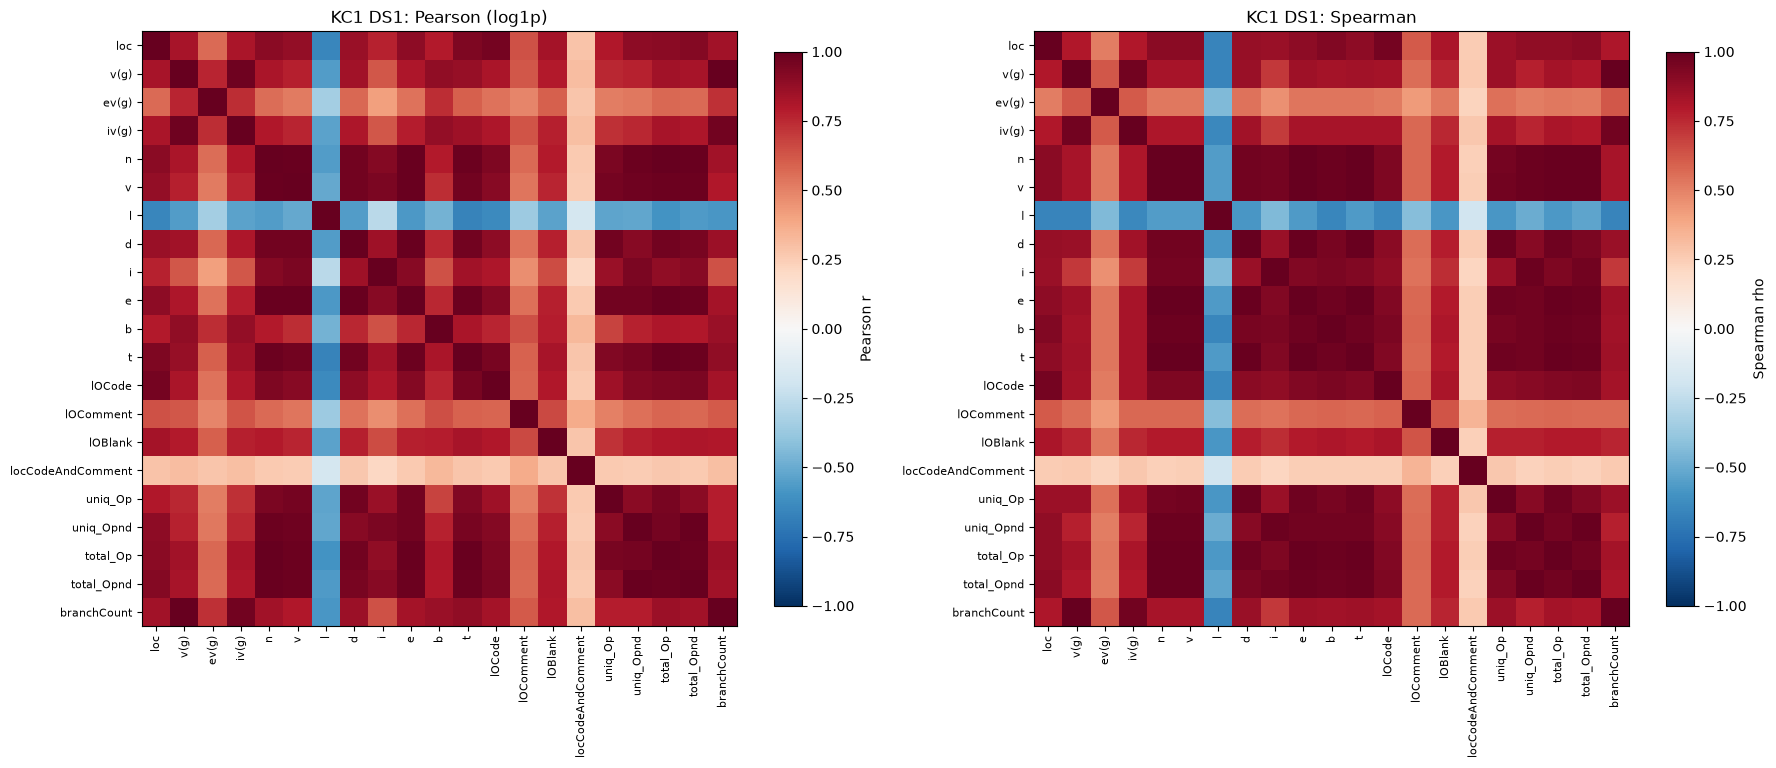

DS1 pearson: pairs with |r| > 0.9: 56 of 210
DS1 spearman: pairs with |rho| > 0.9: 68 of 210


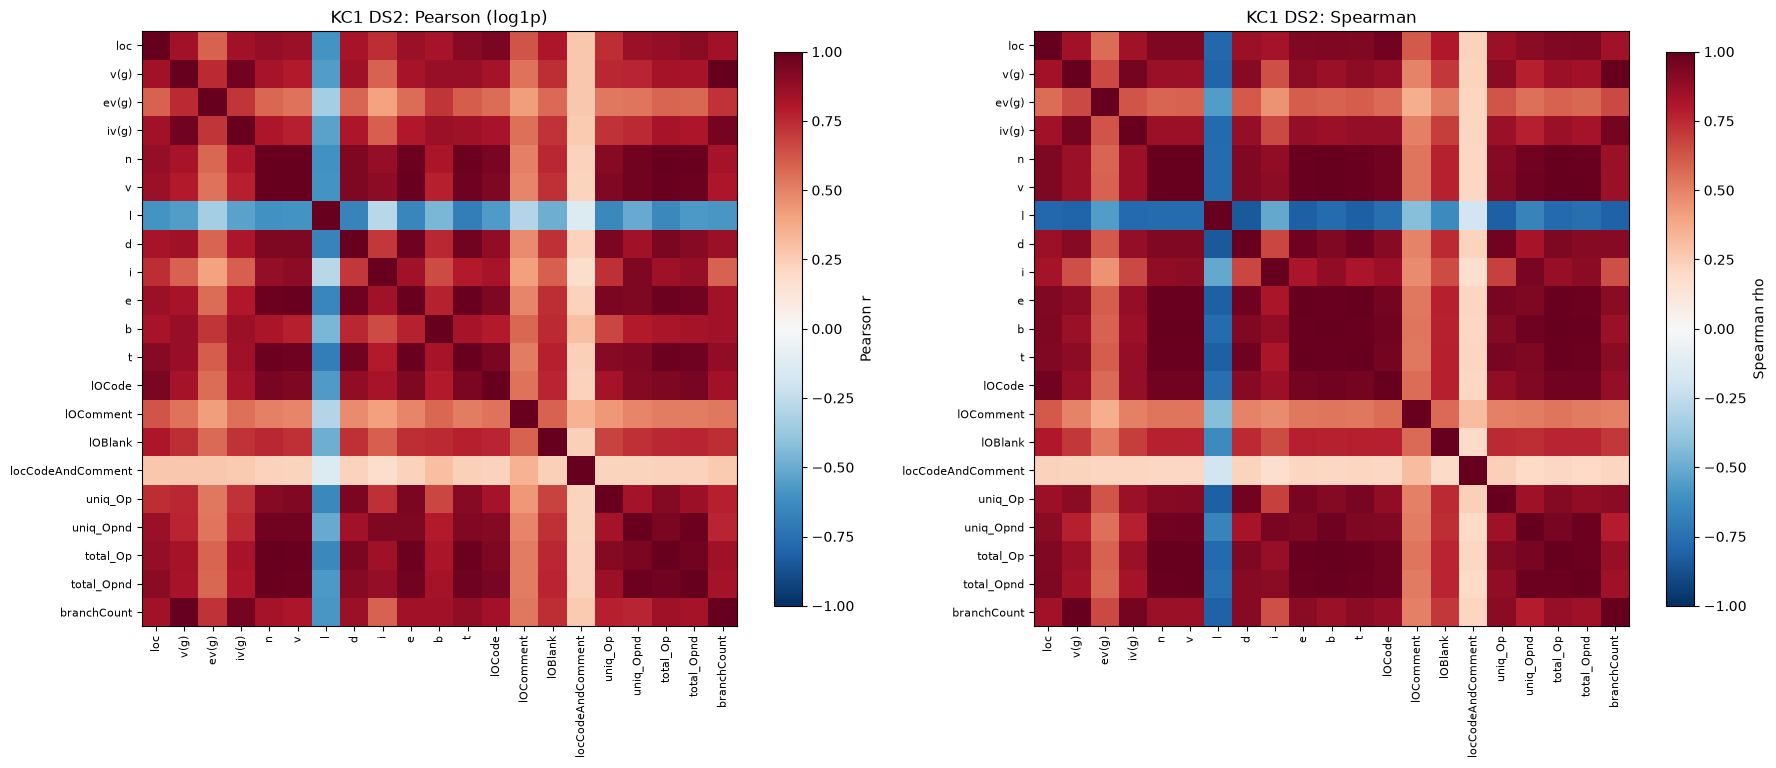

DS2 pearson: pairs with |r| > 0.9: 47 of 210
DS2 spearman: pairs with |rho| > 0.9: 68 of 210


locCodeAndComment    0.247817
ev(g)                0.513379
lOComment            0.548495
l                    0.550218
lOBlank              0.726363
iv(g)                0.761823
v(g)                 0.773172
branchCount          0.775190
i                    0.778372
loc                  0.799863
uniq_Opnd            0.815180
lOCode               0.818286
uniq_Op              0.825507
d                    0.829706
total_Opnd           0.829874
total_Op             0.837507
n                    0.839412
v                    0.839751
t                    0.841825
e                    0.841829
b                    0.842831
Name: mean |rho| with the others, dtype: float64

In [20]:
THRESHOLD = 0.9
symbol = {"pearson": "r", "spearman": "rho"}
pair_tables = {}
for name, X in XS.items():
    corrs = {"pearson": np.log1p(X).corr(method="pearson"), "spearman": X.corr(method="spearman")}
    fig, axes = plt.subplots(1, 2, figsize=(18, 8))
    for ax, (method, corr) in zip(axes, corrs.items()):
        corr.to_csv(OUT_DIR / f"kc1_{name.lower()}_correlation_{method}.csv")
        im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
        ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=90, fontsize=8)
        ax.set_yticks(range(len(FEATURES)), FEATURES, fontsize=8)
        fig.colorbar(im, ax=ax, label=f"{method.capitalize()} {symbol[method]}", shrink=0.8)
        ax.set_title(f"KC1 {name}: {method.capitalize()}" + (" (log1p)" if method == "pearson" else ""))
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"kc1_{name.lower()}_correlation.png", dpi=200)
    plt.show()

    mask = np.triu(np.ones((len(FEATURES), len(FEATURES)), dtype=bool), k=1)
    pairs = pd.DataFrame({m: c.where(mask).stack().dropna() for m, c in corrs.items()})   # 21*20/2 = 210 pairs
    pairs.to_csv(OUT_DIR / f"kc1_{name.lower()}_correlation_pairs.csv")
    pair_tables[name] = pairs
    for method in corrs:
        print(f"{name} {method}: pairs with |{symbol[method]}| > {THRESHOLD}:",
              (pairs[method].abs() > THRESHOLD).sum(), "of", len(pairs))

# Average |correlation| of each feature with the others (DS1, Spearman): which features are NOT size-like?
sp = XS["DS1"].corr(method="spearman")
mean_abs = ((sp.abs().sum() - 1) / (len(FEATURES) - 1)).sort_values().rename("mean |rho| with the others")
mean_abs

### 4d: Feature distributions

Histograms of the raw values and of the log1p values (on the raw scale a few very large modules squeeze most
points near 0), DS1 vs DS2.

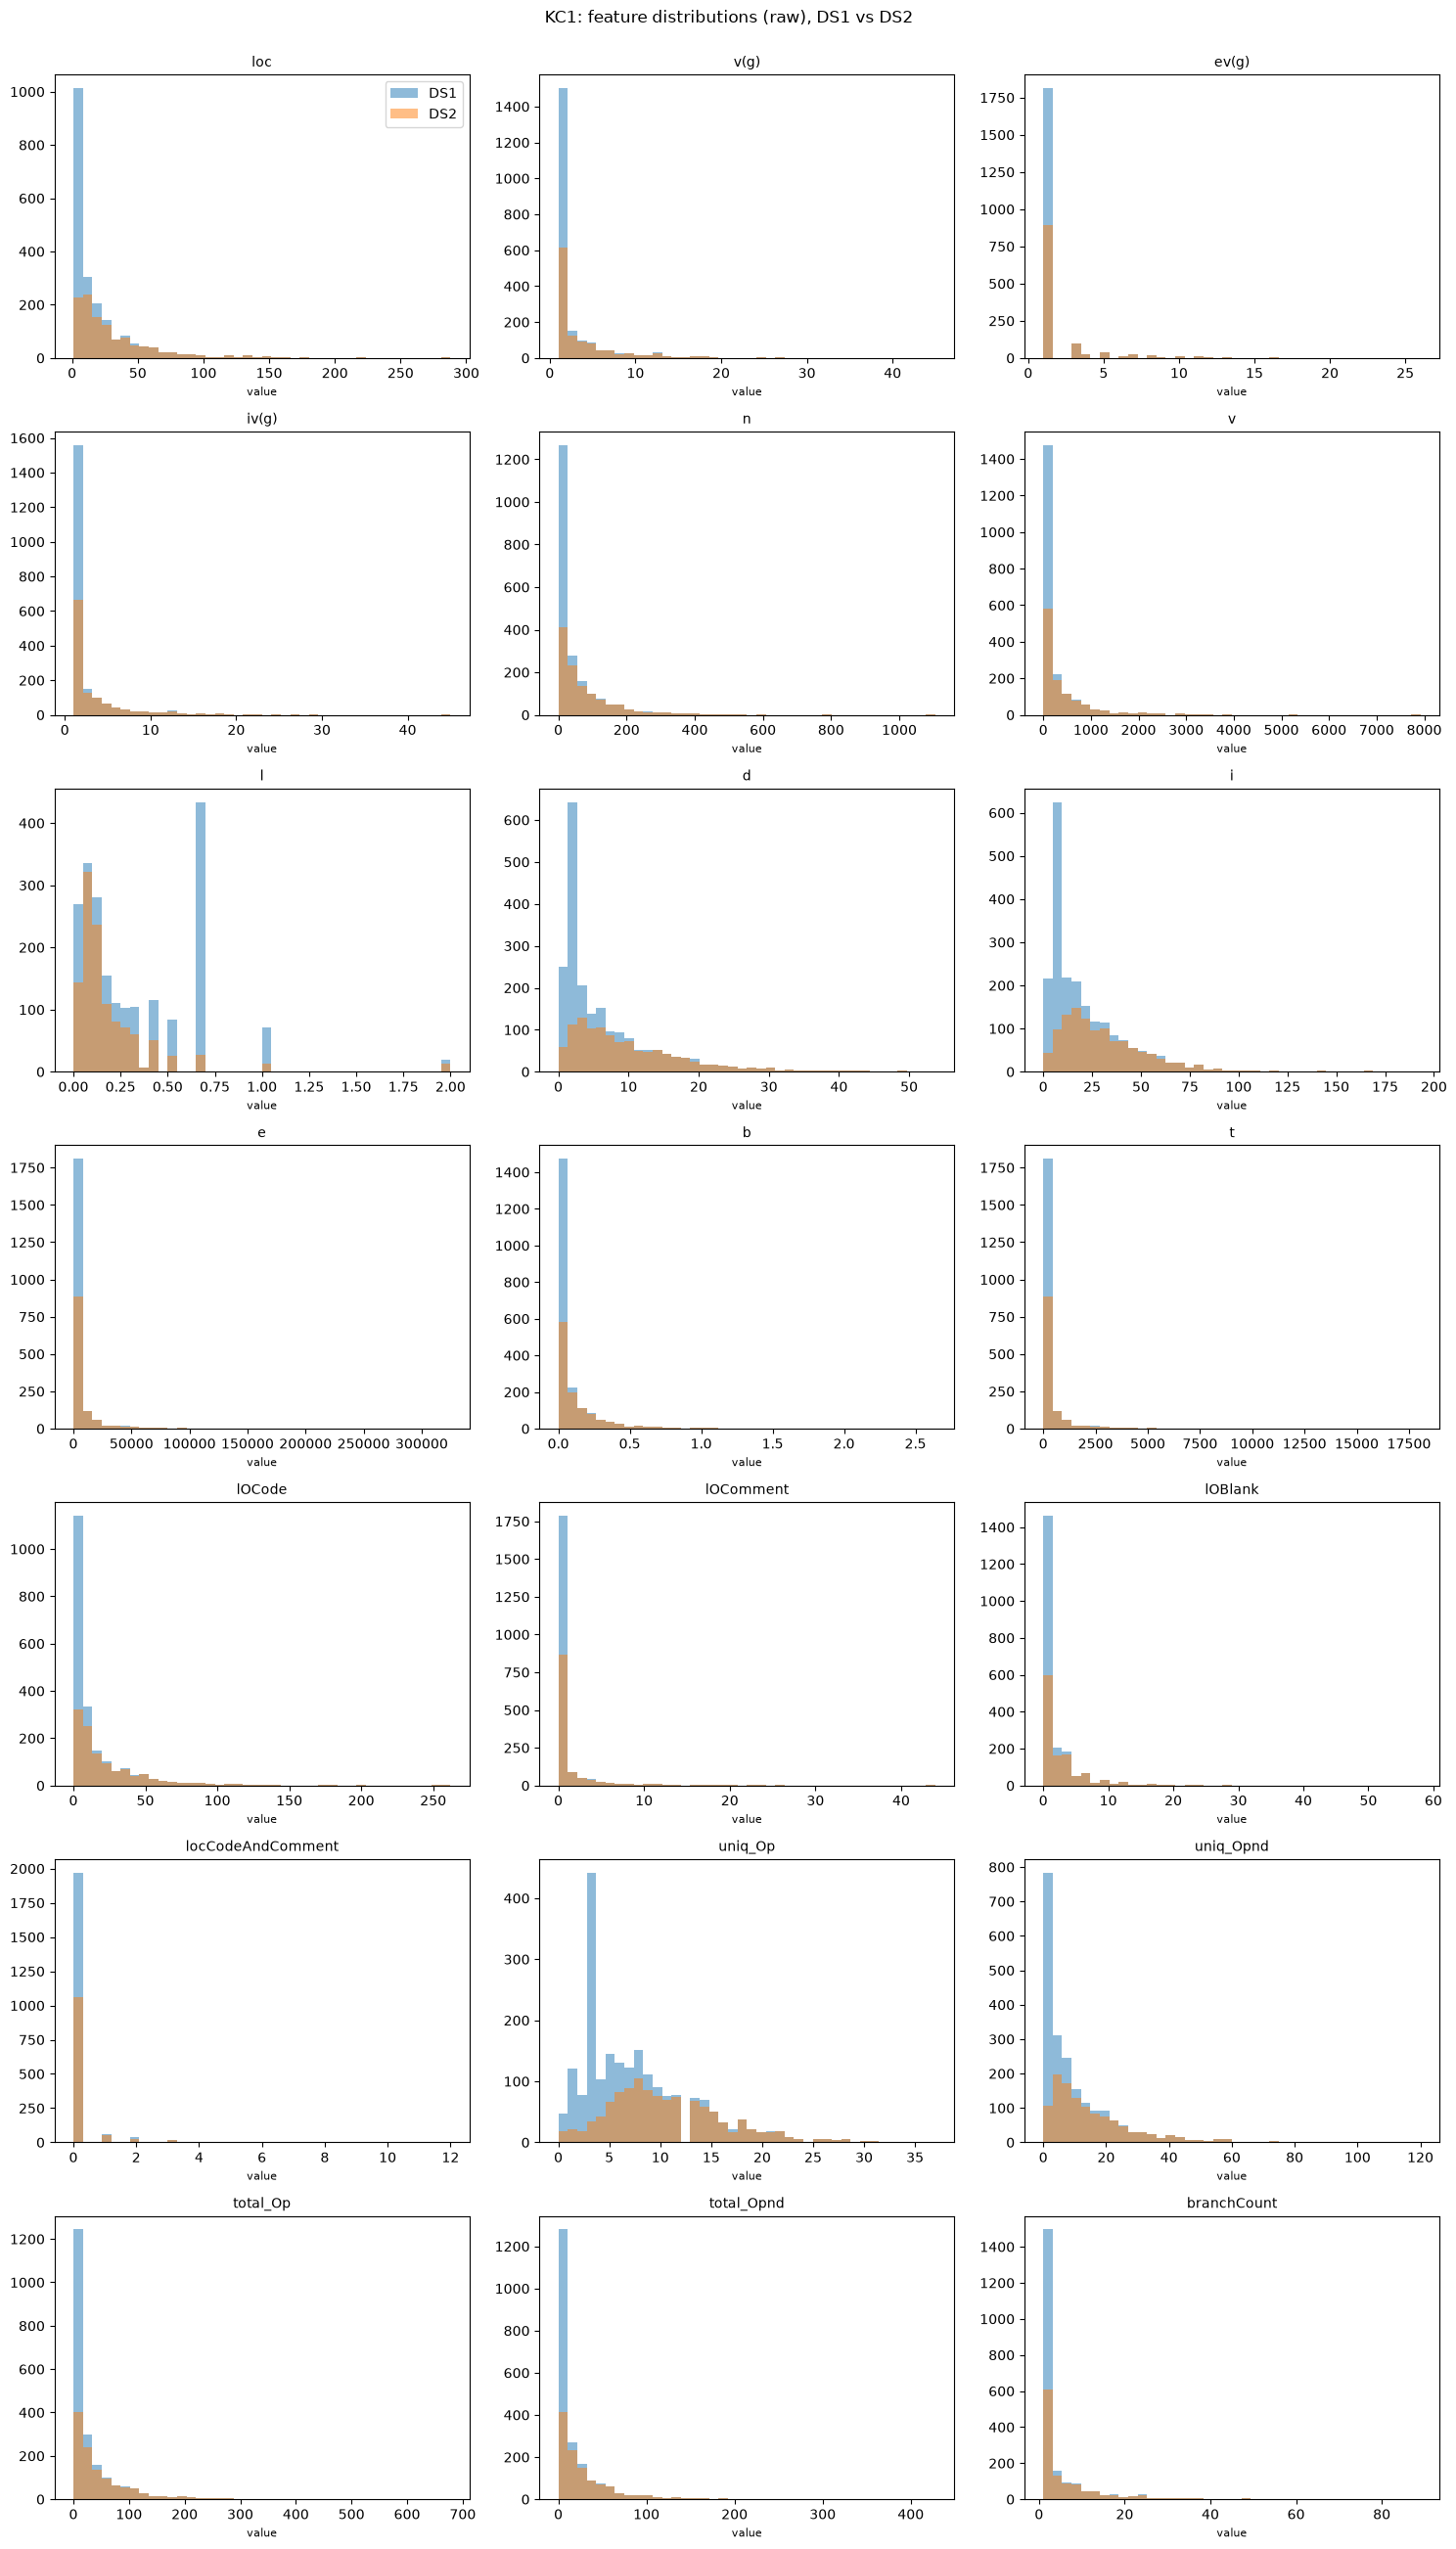

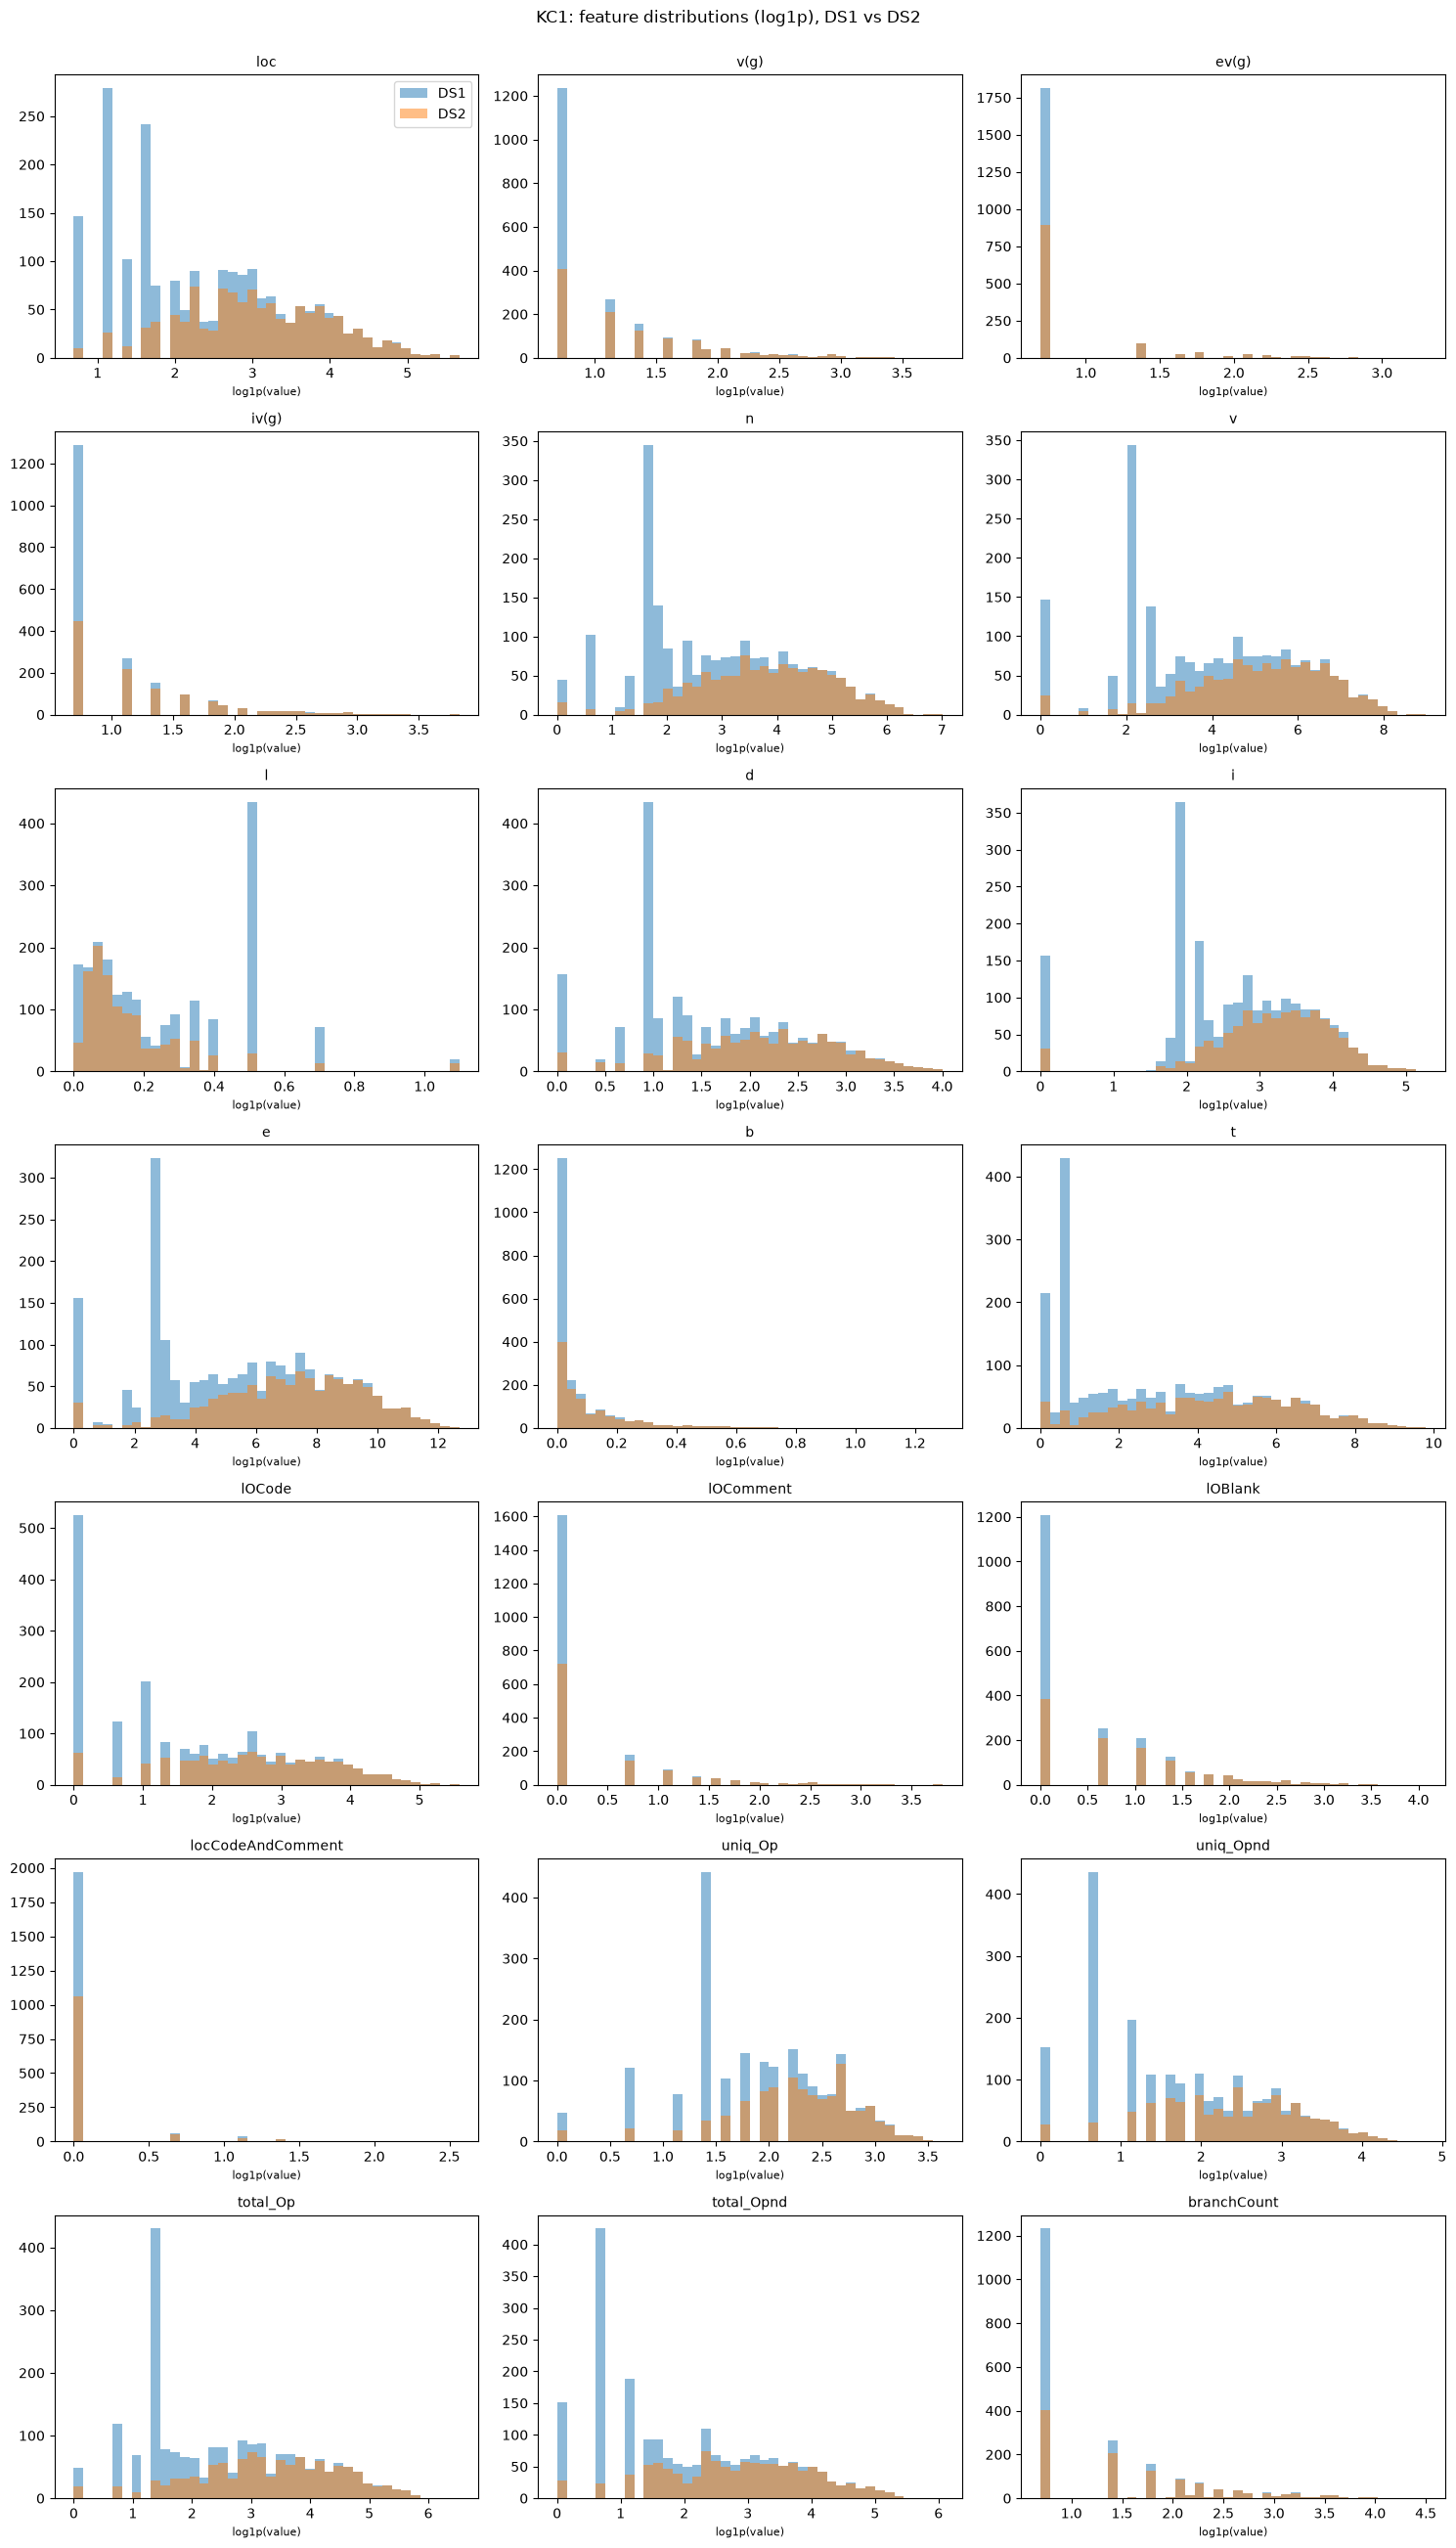

In [21]:
TRANSFORMS = {"raw": lambda v: v, "log1p": np.log1p}
ncol = 3
for tname, tf in TRANSFORMS.items():
    fig, axes = plt.subplots(int(np.ceil(len(FEATURES) / ncol)), ncol, figsize=(15, 26))
    for ax, f in zip(axes.ravel(), FEATURES):
        bins = np.histogram_bin_edges(tf(XS["DS1"][f]), bins=40)
        for name, X in XS.items():
            ax.hist(tf(X[f]), bins=bins, alpha=0.5, label=name)
        ax.set_title(f, fontsize=10)
        ax.set_xlabel("value" if tname == "raw" else "log1p(value)", fontsize=8)
    for ax in axes.ravel()[len(FEATURES):]:
        ax.axis("off")
    axes.ravel()[0].legend()
    fig.suptitle(f"KC1: feature distributions ({tname}), DS1 vs DS2", y=1.0)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"kc1_distributions_{tname}.png", dpi=200)
    plt.show()

### 4e: PCA explained variance

PCA on the correlation matrix (= PCA on z-scored features) of the log1p values, computed with NumPy as for WDBC.
Exploration only: clustering is not run on these components.

DS1: components for 80/90/95/99%: [2, 4, 6, 10]; Kaiser (eigenvalue > 1): 2; PC1 explains 76.8%
DS2: components for 80/90/95/99%: [2, 4, 7, 10]; Kaiser (eigenvalue > 1): 2; PC1 explains 75.4%


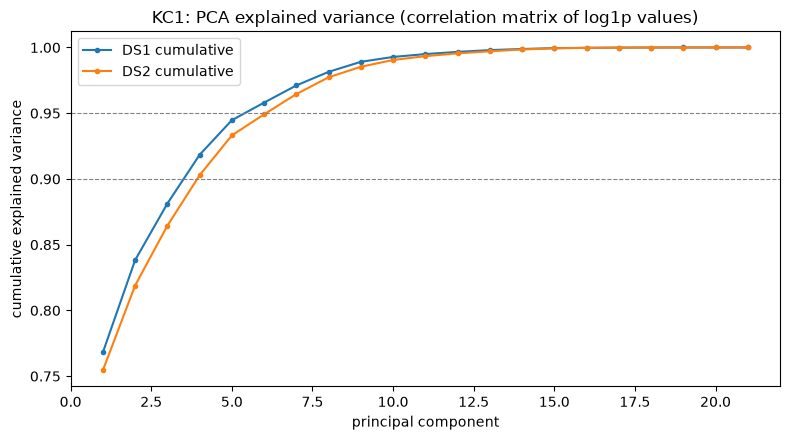

DS1                   DS2           
          eigenvalue cumulative eigenvalue cumulative
component                                            
1          16.129076   0.768051  15.842845   0.754421
2           1.473960   0.838240   1.355154   0.818952
3           0.903438   0.881261   0.954786   0.864418
4           0.778970   0.918354   0.806225   0.902810
5           0.553051   0.944690   0.636574   0.933123
6           0.280672   0.958056   0.336175   0.949131
7           0.274470   0.971126   0.323767   0.964549
8           0.216890   0.981454   0.268083   0.977315

In [22]:
pca_tables = {}
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, X in XS.items():
    eigvals = np.linalg.eigvalsh(np.log1p(X).corr(method="pearson").to_numpy())[::-1]
    pca = pd.DataFrame({"component": np.arange(1, len(eigvals) + 1), "eigenvalue": eigvals,
                        "explained_variance_ratio": eigvals / eigvals.sum()})
    pca["cumulative"] = pca["explained_variance_ratio"].cumsum()
    pca.to_csv(OUT_DIR / f"kc1_{name.lower()}_pca_explained_variance.csv", index=False)
    pca_tables[name] = pca
    ks = {lvl: int((pca["cumulative"] >= lvl).idxmax()) + 1 for lvl in (0.80, 0.90, 0.95, 0.99)}
    print(f"{name}: components for 80/90/95/99%: {list(ks.values())};"
          f" Kaiser (eigenvalue > 1): {(pca['eigenvalue'] > 1).sum()};"
          f" PC1 explains {pca['explained_variance_ratio'].iloc[0]:.1%}")
    ax.plot(pca["component"], pca["cumulative"], marker="o", markersize=3, label=f"{name} cumulative")
for level in (0.90, 0.95):
    ax.axhline(level, linestyle="--", linewidth=0.8, color="grey")
ax.set_xlabel("principal component")
ax.set_ylabel("cumulative explained variance")
ax.set_title("KC1: PCA explained variance (correlation matrix of log1p values)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "kc1_pca_explained_variance.png", dpi=200)
plt.show()
pd.concat({n: t.set_index("component")[["eigenvalue", "cumulative"]] for n, t in pca_tables.items()}, axis=1).head(8)

### 4f: Weight of the repeated feature vectors in DS1

In DS1 identical feature vectors are kept; for FCM each copy counts as a separate point.

In [23]:
X1 = DS["DS1"]
vec = (X1.groupby(FEATURES, sort=False)["defects"].agg(copies="size", defective="sum")
       .sort_values("copies", ascending=False).reset_index())
vec["share_of_DS1"] = vec["copies"] / len(X1)
vec["cumulative_share"] = vec["share_of_DS1"].cumsum()
vec.to_csv(OUT_DIR / "kc1_ds1_repeated_vectors.csv", index=False)

print("distinct vectors:", len(vec), " of which repeated (>= 2 copies):", (vec["copies"] >= 2).sum())
print("rows that belong to a repeated vector:", int(vec.loc[vec["copies"] >= 2, "copies"].sum()), "of", len(X1))
for k in (1, 5, 10, 20):
    print(f"top {k} vectors cover {vec['share_of_DS1'].head(k).sum():.1%} of DS1")
print("defective share: repeated vectors", f"{vec.loc[vec['copies'] >= 2, 'defective'].sum() / vec.loc[vec['copies'] >= 2, 'copies'].sum():.1%},",
      "unique vectors", f"{vec.loc[vec['copies'] == 1, 'defective'].mean():.1%}")
vec.head(10)[["loc", "n", "v(g)", "uniq_Op", "uniq_Opnd", "total_Op", "total_Opnd", "copies", "defective",
              "share_of_DS1", "cumulative_share"]]

distinct vectors: 1183  of which repeated (>= 2 copies): 176
rows that belong to a repeated vector: 1089 of 2096
top 1 vectors cover 5.3% of DS1
top 5 vectors cover 19.0% of DS1
top 10 vectors cover 24.2% of DS1
top 20 vectors cover 29.9% of DS1
defective share: repeated vectors 3.1%, unique vectors 28.9%


,loc,n,v(g),uniq_Op,uniq_Opnd,total_Op,total_Opnd,copies,defective,share_of_DS1,cumulative_share
0,2.0,4.0,1.0,3.0,1.0,3.0,1.0,112,0,0.053435,0.053435
1,1.0,4.0,1.0,3.0,1.0,3.0,1.0,104,0,0.049618,0.103053
2,3.0,1.0,1.0,1.0,0.0,1.0,0.0,73,2,0.034828,0.137882
3,4.0,4.0,1.0,3.0,1.0,3.0,1.0,59,4,0.028149,0.166031
4,2.0,5.0,1.0,3.0,2.0,3.0,2.0,50,0,0.023855,0.189885
5,4.0,4.0,1.0,3.0,1.0,3.0,1.0,31,0,0.014790,0.204676
6,2.0,3.0,1.0,2.0,1.0,2.0,1.0,22,1,0.010496,0.215172
7,4.0,5.0,1.0,4.0,1.0,4.0,1.0,20,1,0.009542,0.224714
8,4.0,3.0,1.0,2.0,1.0,2.0,1.0,20,0,0.009542,0.234256
9,4.0,7.0,1.0,5.0,2.0,5.0,2.0,17,0,0.008111,0.242366


## Step 5: Preprocessing variants

Decisions (Stefan, 18 Nov, after Step 4):

- **Feature sets.** Main: `measured13`, the 13 metrics that are counted directly from the code: 5 line counts,
  3 McCabe metrics, the 4 base Halstead counts (`uniq_Op`, `uniq_Opnd`, `total_Op`, `total_Opnd`) and `branchCount`.
  The 8 Halstead measures `n, v, l, d, i, e, b, t` are dropped there: they are computed from the 4 base counts
  (`n` = N1 + N2 and the formulas of rules 13-18 checked in 2b; `b` is the Halstead error estimate, also derived).
  Comparison: `all21`, the dataset as published (as for WDBC).
- **Transform.** log1p for all variants: 21/21 features have |skew| > 1 raw (4b) and 16/21 contain 0, so log10 is not possible.
- **Scaling.** z-score (population std, ddof = 0) and min-max, after log1p (as for the NASA data).
- **Data.** DS1 (DS', main) and DS2 (DS'', comparison).

The label `defects` is kept aside in `Y` and is **not** used by any preprocessing or clustering step.

In [24]:
DERIVED = ["n", "v", "l", "d", "i", "e", "b", "t"]
FSETS = {
    "measured13": [f for f in FEATURES if f not in DERIVED],
    "all21": FEATURES,
}
assert len(FSETS["measured13"]) == 13

def zscore(A):
    return (A - A.mean(axis=0)) / A.std(axis=0)

def minmax(A):
    return (A - A.min(axis=0)) / (A.max(axis=0) - A.min(axis=0))

SCALERS = {"log1p_zscore": zscore, "log1p_minmax": minmax}

Y = {name: d["defects"].to_numpy() for name, d in DS.items()}      # kept aside, evaluation only
data = {}                                                            # (version, feature set, variant) -> array
for ds_name, d in DS.items():
    for fs_name, cols in FSETS.items():
        A_raw = d[cols].to_numpy(dtype=float)
        assert (A_raw >= 0).all(), "log1p needs non-negative values"
        for v_name, scale in SCALERS.items():
            A = scale(np.log1p(A_raw))
            data[(ds_name, fs_name, v_name)] = A
            pd.DataFrame(A, columns=cols).to_csv(OUT_DIR / f"kc1_{ds_name.lower()}_{fs_name}_{v_name}.csv", index=False)
            print(f"{ds_name} {fs_name:10s} {v_name:13s} shape={A.shape}  "
                  f"std range=[{A.std(0).min():.3f}, {A.std(0).max():.3f}]  value range=[{A.min():.3f}, {A.max():.3f}]")
print("\nmeasured13:", FSETS["measured13"])

DS1 measured13 log1p_zscore  shape=(2096, 13)  std range=[1.000, 1.000]  value range=[-2.751, 9.223]
DS1 measured13 log1p_minmax  shape=(2096, 13)  std range=[0.106, 0.254]  value range=[0.000, 1.000]
DS1 all21      log1p_zscore  shape=(2096, 21)  std range=[1.000, 1.000]  value range=[-2.751, 9.560]
DS1 all21      log1p_minmax  shape=(2096, 21)  std range=[0.099, 0.254]  value range=[0.000, 1.000]
DS2 measured13 log1p_zscore  shape=(1163, 13)  std range=[1.000, 1.000]  value range=[-3.852, 7.352]
DS2 measured13 log1p_minmax  shape=(1163, 13)  std range=[0.131, 0.237]  value range=[0.000, 1.000]
DS2 all21      log1p_zscore  shape=(1163, 21)  std range=[1.000, 1.000]  value range=[-3.852, 7.709]
DS2 all21      log1p_minmax  shape=(1163, 21)  std range=[0.117, 0.237]  value range=[0.000, 1.000]

measured13: ['loc', 'v(g)', 'ev(g)', 'iv(g)', 'lOCode', 'lOComment', 'lOBlank', 'locCodeAndComment', 'uniq_Op', 'uniq_Opnd', 'total_Op', 'total_Opnd', 'branchCount']


### 5a: How much each feature weighs in the distance

As for WDBC: each feature's **share of the total variance** is its average share in the squared Euclidean distances.
Under z-score every share is 1/p by construction; under min-max the shares depend on each feature's distribution
(e.g. a feature that is 0 for 94% of the modules gets little weight).

In [25]:
shares = {}
for (ds_name, fs_name, v_name), A in data.items():
    if v_name == "log1p_minmax":
        shares[(ds_name, fs_name)] = pd.Series(A.var(axis=0) / A.var(axis=0).sum(), index=FSETS[fs_name])
shares = pd.DataFrame(shares)
shares.columns = [f"{a} {b}" for a, b in shares.columns]
shares = shares.sort_values("DS1 measured13", ascending=False)
shares.to_csv(OUT_DIR / "kc1_minmax_variance_share.csv", index_label="feature")
for col in shares:
    s = shares[col].dropna()
    print(f"{col}: max/min share = {s.max() / s.min():.1f}  (1/p = {1 / len(s):.3f})")
shares.round(4)

DS1 measured13: max/min share = 5.8  (1/p = 0.077)
DS1 all21: max/min share = 6.6  (1/p = 0.048)
DS2 measured13: max/min share = 3.3  (1/p = 0.077)
DS2 all21: max/min share = 4.1  (1/p = 0.048)


,DS1 measured13,DS1 all21,DS2 measured13,DS2 all21
lOCode,0.1243,0.0743,0.0840,0.0560
loc,0.1000,0.0598,0.0715,0.0476
uniq_Opnd,0.0964,0.0576,0.0685,0.0457
total_Opnd,0.0961,0.0574,0.0721,0.0481
branchCount,0.0911,0.0544,0.1118,0.0745
total_Op,0.0811,0.0485,0.0674,0.0449
lOBlank,0.0751,0.0449,0.0908,0.0605
v(g),0.0724,0.0432,0.0937,0.0625
uniq_Op,0.0720,0.0430,0.0538,0.0359
iv(g),0.0622,0.0372,0.0826,0.0551


### 5b: Distributions after each preprocessing variant (DS1)

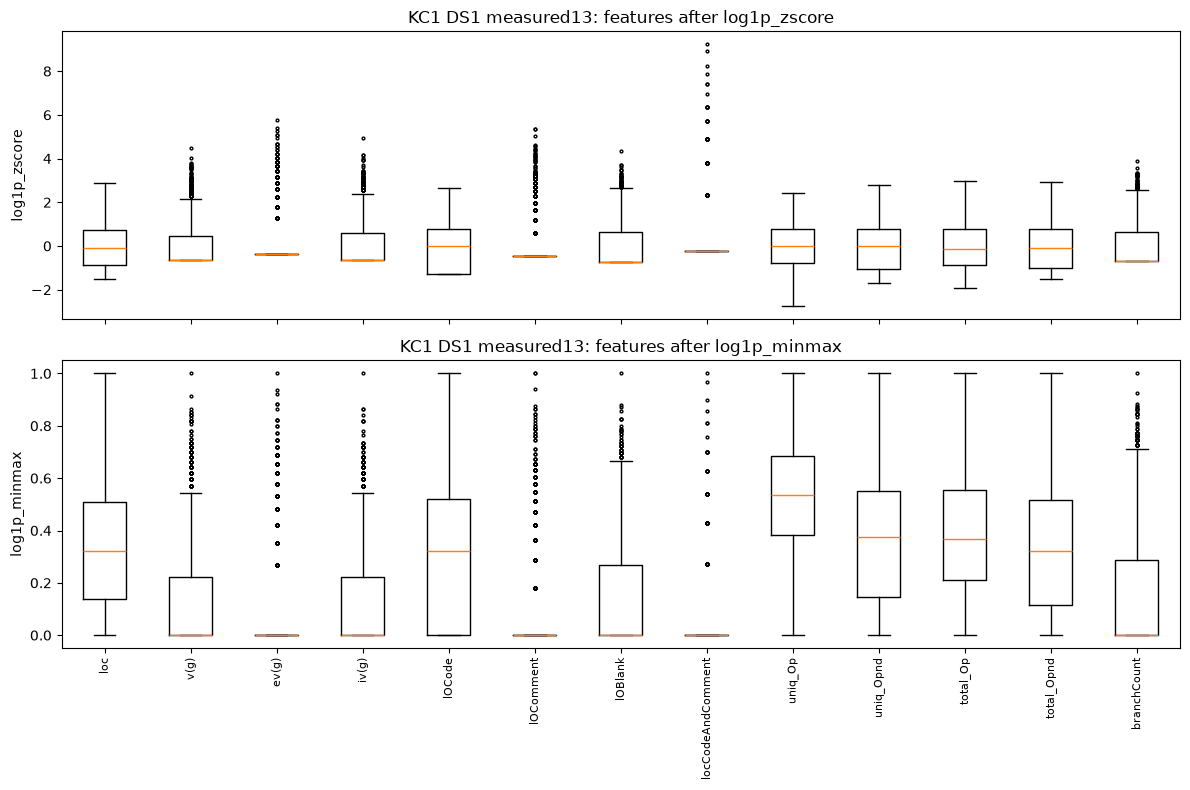

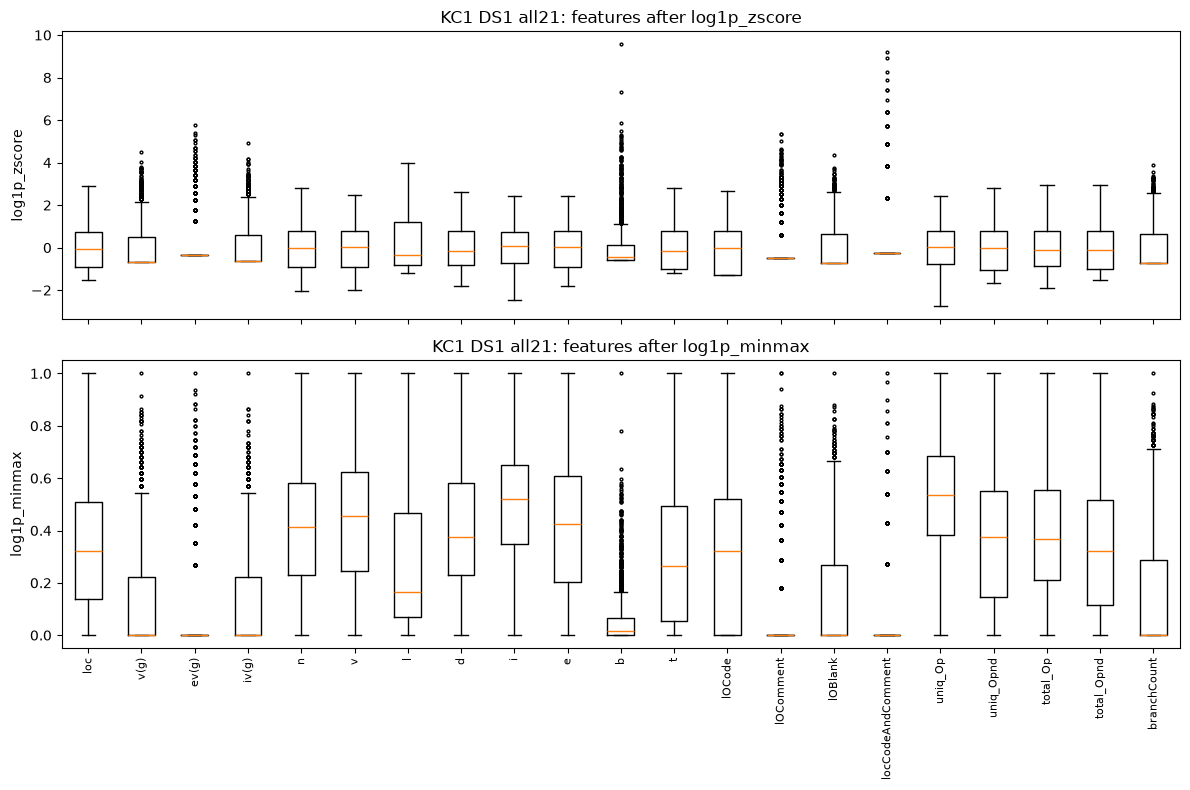

In [26]:
for fs_name, cols in FSETS.items():
    fig, axes = plt.subplots(len(SCALERS), 1, figsize=(12, 4 * len(SCALERS)), sharex=True)
    for ax, v_name in zip(axes, SCALERS):
        ax.boxplot(data[("DS1", fs_name, v_name)], whis=1.5, flierprops={"markersize": 2})
        ax.set_ylabel(v_name)
        ax.set_title(f"KC1 DS1 {fs_name}: features after {v_name}")
    axes[-1].set_xticks(range(1, len(cols) + 1), cols, rotation=90, fontsize=8)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"kc1_ds1_{fs_name}_scaling.png", dpi=200)
    plt.show()

## Step 6: Number of clusters c and fuzzifier m

Same procedure as for WDBC and the NASA exoplanet data: FCM from `src/fcm.py` (cross-checked against scikit-fuzzy in the
WDBC notebook), for every (version, feature set, variant) of Step 5, c = 2 ... 10 and m in `M_GRID`,
`N_INIT` = 10 random starts (seeds `SEED`, `SEED + 1`, ...), the run with the lowest J is kept.
`M_GRID` also contains the dimension-dependent fuzzifier of Winkler et al. (2011), m = (2 + p) / p:
1.154 for p = 13 and 1.095 for p = 21.

The label `defects` is **not** used here: only the internal validity indices (PC, NPC, PE, NPE, XB, FS; lecture 05a,
slides 76-82) and the prototype diagnostics (are the c prototypes distinct?). For each m, compare the indices
**across c**, not across m. About 5,000 FCM runs; this may take several minutes.

In [27]:
import sys, time
sys.path.insert(0, "..")          # make src/ importable (this notebook is in src/code_analysis/)
import importlib
import fcm
importlib.reload(fcm)

SEED = 42
FCM_EPS, FCM_MAX_ITER = 1e-5, 1000
C_RANGE = range(2, 11)
N_INIT = 10
M_BASE = [1.1, 1.25, 1.5, 1.75, 2.0, 2.5]
INDICES = {"PC": "max", "NPC": "max", "PE": "min", "NPE": "min", "XB": "min", "FS": "min"}

grid_rows, grid_runs = [], {}     # grid_runs: (version, feature set, variant, m, c) -> best FCMResult
t0 = time.time()
for (ds_name, fs_name, v_name), A in data.items():
    p_feat = A.shape[1]
    m_grid = sorted(set(M_BASE) | {round((2 + p_feat) / p_feat, 3)})
    for m in m_grid:
        for c in C_RANGE:
            best, info = fcm.fcm_multistart(A, c, m=m, n_init=N_INIT, seed=SEED, eps=FCM_EPS, max_iter=FCM_MAX_ITER)
            grid_runs[(ds_name, fs_name, v_name, m, c)] = best
            grid_rows.append({
                "version": ds_name, "fset": fs_name, "variant": v_name, "m": m, "c": c,
                **fcm.validity_indices(A, best, m),
                **fcm.prototype_diagnostics(A, best),
                "J": best.J, "iterations": best.n_iter,
                "n_at_best": info["n_at_best"], "n_not_converged": info["n_not_converged"],
            })
        g = pd.DataFrame(grid_rows).query("version == @ds_name and fset == @fs_name and variant == @v_name and m == @m")
        print(f"{ds_name} {fs_name:10s} {v_name:13s} m={m:<6} distinct prototypes per c: {g['n_distinct'].tolist()}  "
              f"not converged: {g['n_not_converged'].tolist()}  ({time.time() - t0:.0f} s)")

grid = pd.DataFrame(grid_rows)
grid.to_csv(OUT_DIR / "kc1_c_m_grid.csv", index=False)

DS1 measured13 log1p_zscore  m=1.1    distinct prototypes per c: [2, 3, 4, 5, 6, 7, 8, 9, 10]  not converged: [0, 0, 0, 0, 0, 0, 0, 0, 0]  (10 s)
DS1 measured13 log1p_zscore  m=1.154  distinct prototypes per c: [2, 3, 4, 5, 6, 7, 8, 9, 10]  not converged: [0, 0, 0, 0, 0, 0, 0, 0, 0]  (19 s)
DS1 measured13 log1p_zscore  m=1.25   distinct prototypes per c: [2, 3, 4, 5, 6, 7, 8, 9, 10]  not converged: [0, 0, 0, 0, 0, 0, 0, 0, 0]  (31 s)
DS1 measured13 log1p_zscore  m=1.5    distinct prototypes per c: [2, 3, 4, 5, 6, 7, 8, 9, 10]  not converged: [0, 0, 0, 0, 0, 0, 0, 0, 0]  (41 s)
DS1 measured13 log1p_zscore  m=1.75   distinct prototypes per c: [2, 3, 4, 5, 6, 7, 8, 9, 10]  not converged: [0, 0, 0, 0, 0, 0, 0, 0, 0]  (50 s)
DS1 measured13 log1p_zscore  m=2.0    distinct prototypes per c: [2, 3, 4, 5, 6, 7, 8, 9, 10]  not converged: [0, 0, 0, 0, 0, 0, 0, 0, 0]  (55 s)
DS1 measured13 log1p_zscore  m=2.5    distinct prototypes per c: [2, 3, 4, 5, 6, 7, 8, 9, 10]  not converged: [0, 0, 0, 0, 0

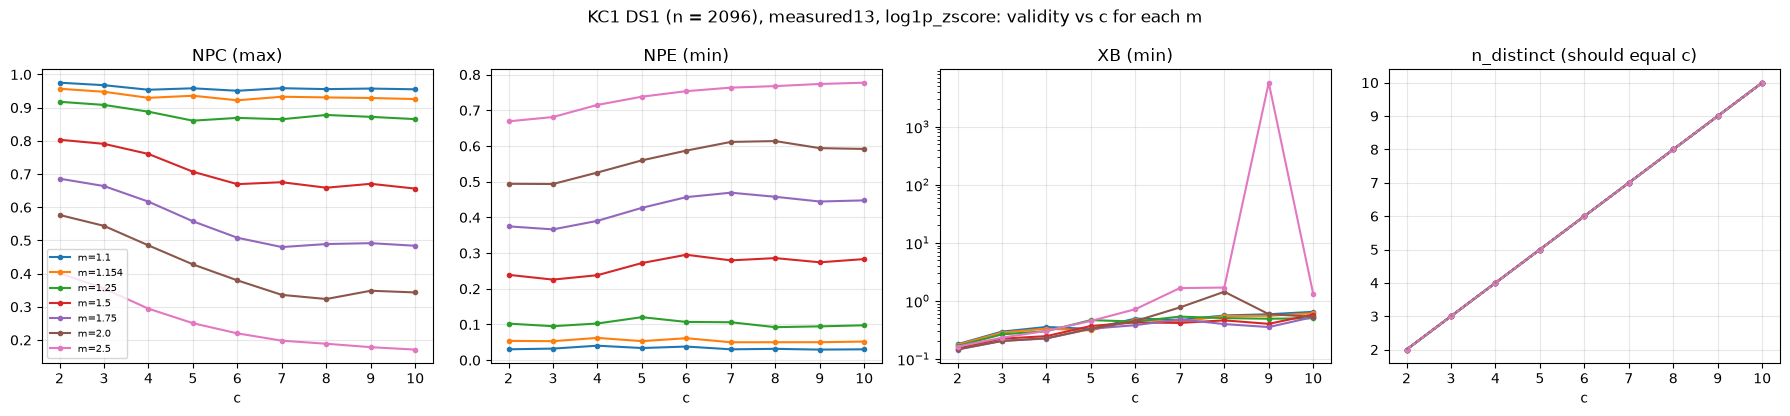

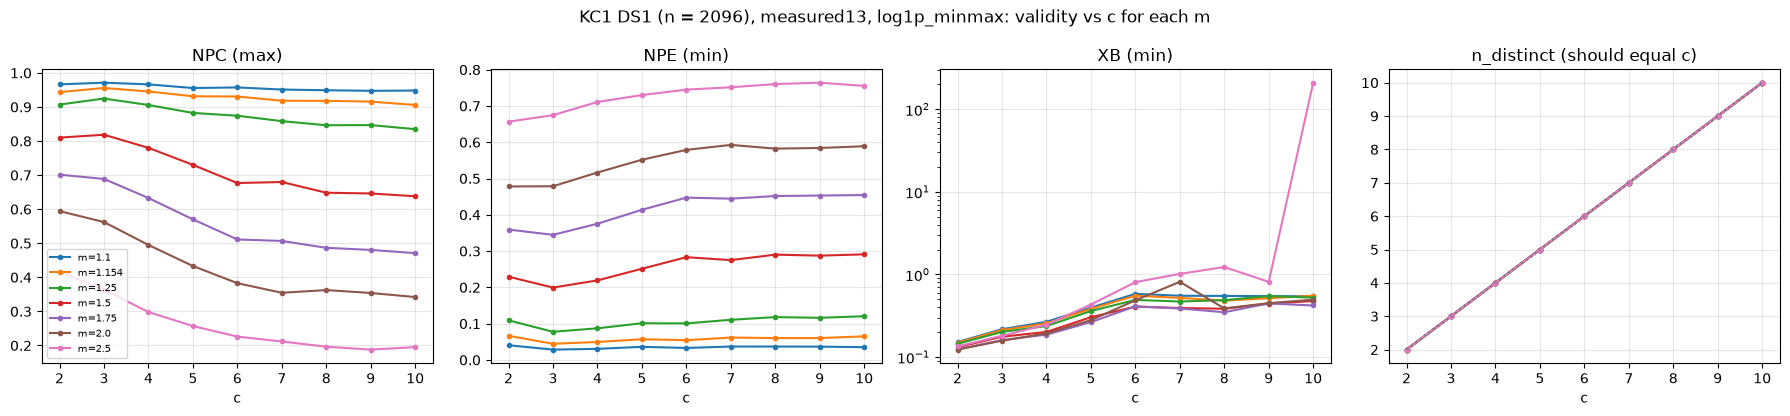

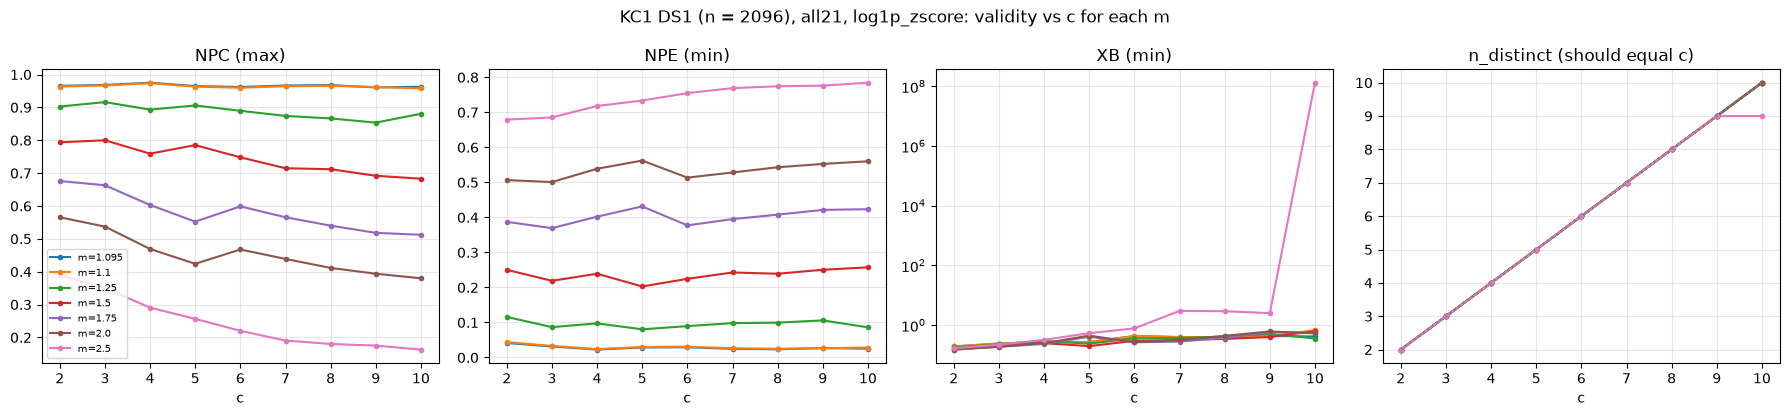

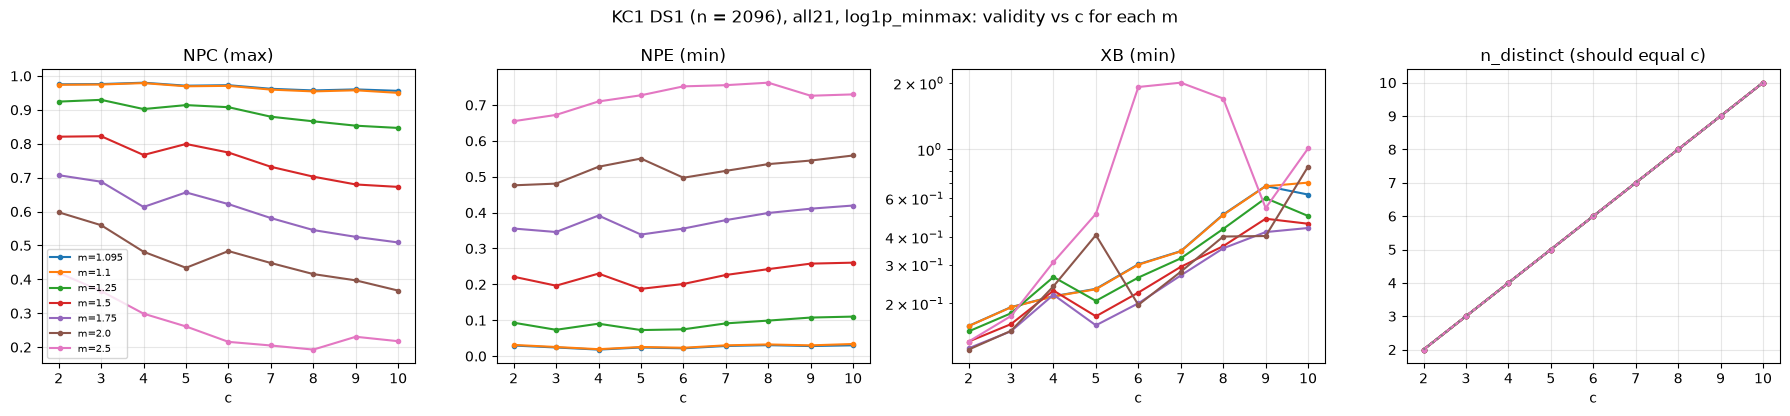

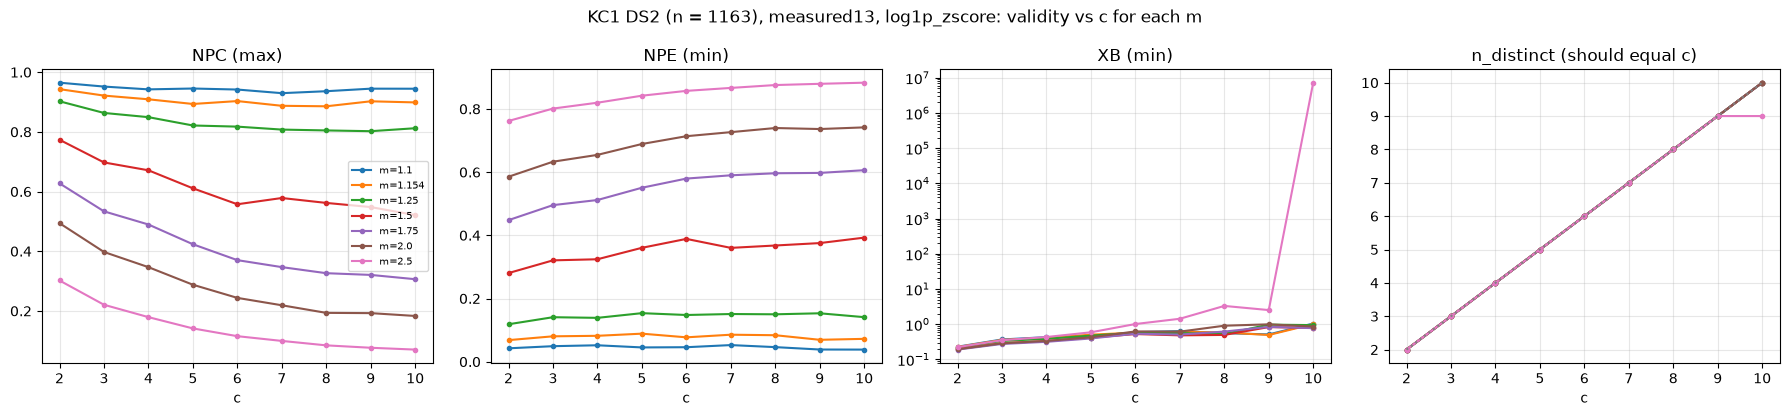

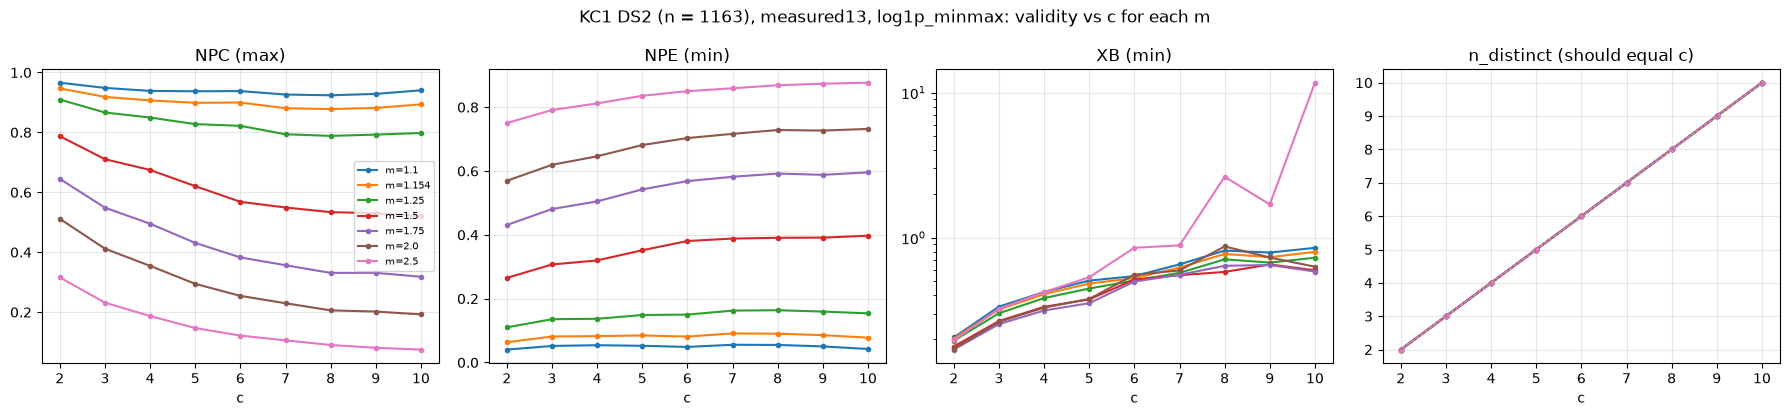

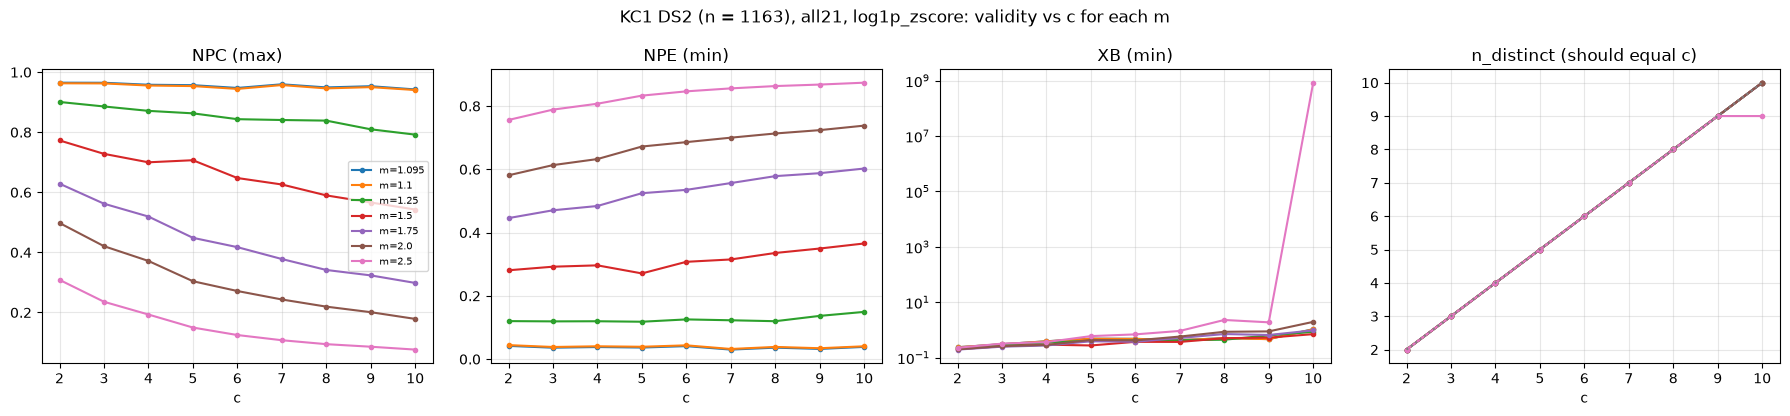

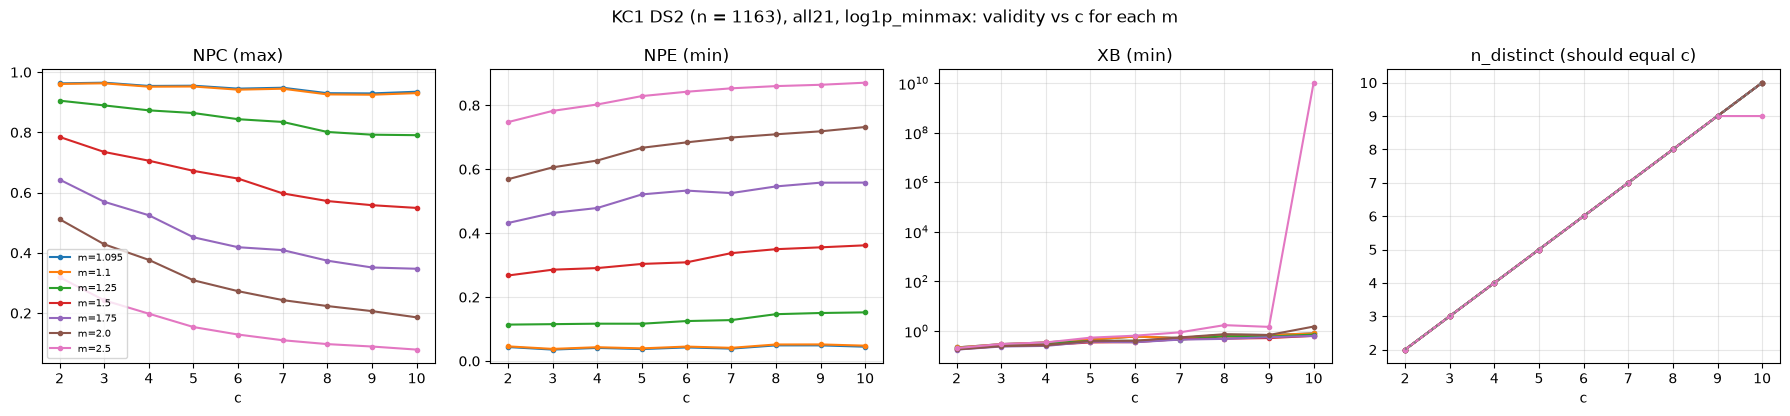

In [28]:
PANELS = [("NPC", "max", False), ("NPE", "min", False), ("XB", "min", True), ("n_distinct", "should equal c", False)]

for (ds_name, fs_name, v_name), g in grid.groupby(["version", "fset", "variant"], sort=False):
    fig, axes = plt.subplots(1, len(PANELS), figsize=(18, 4.2), sharex=True)
    for ax, (col, best_dir, logy) in zip(axes, PANELS):
        for m, gm in g.groupby("m"):
            ax.plot(gm["c"], gm[col], marker="o", markersize=3, label=f"m={m}")
        if col == "n_distinct":
            ax.plot(list(C_RANGE), list(C_RANGE), color="grey", linestyle=":", label="= c")
        if logy:
            ax.set_yscale("log")
        ax.set_title(f"{col} ({best_dir})")
        ax.set_xlabel("c")
        ax.set_xticks(list(C_RANGE))
        ax.grid(alpha=0.3)
    axes[0].legend(fontsize=7)
    fig.suptitle(f"KC1 {ds_name} (n = {len(DS[ds_name])}), {fs_name}, {v_name}: validity vs c for each m")
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"kc1_c_m_grid_{ds_name.lower()}_{fs_name}_{v_name}.png", dpi=200)
    plt.show()

In [29]:
# For each (version, feature set, variant, m): the c preferred by each index, among non-degenerate partitions only
# (all c prototypes distinct). "-" means no valid c for that m.
pref_rows = []
for (ds_name, fs_name, v_name, m), g in grid.groupby(["version", "fset", "variant", "m"], sort=False):
    valid = g[g["n_distinct"] == g["c"]].set_index("c")
    row = {"version": ds_name, "fset": fs_name, "variant": v_name, "m": m,
           "valid c": ",".join(map(str, valid.index)) if len(valid) else "-"}
    for idx, d in INDICES.items():
        row[idx] = (valid[idx].idxmax() if d == "max" else valid[idx].idxmin()) if len(valid) else "-"
    pref_rows.append(row)
grid_pref = pd.DataFrame(pref_rows)
grid_pref.to_csv(OUT_DIR / "kc1_c_m_grid_preferred.csv", index=False)
grid_pref

,version,fset,variant,m,valid c,PC,NPC,PE,NPE,XB,FS
0,DS1,measured13,log1p_zscore,1.100,"2,3,4,5,6,7,8,9,10",2,2,2,9,2,10
1,DS1,measured13,log1p_zscore,1.154,"2,3,4,5,6,7,8,9,10",2,2,2,7,2,10
2,DS1,measured13,log1p_zscore,1.250,"2,3,4,5,6,7,8,9,10",2,2,2,8,2,10
3,DS1,measured13,log1p_zscore,1.500,"2,3,4,5,6,7,8,9,10",2,2,2,3,2,10
4,DS1,measured13,log1p_zscore,1.750,"2,3,4,5,6,7,8,9,10",2,2,2,3,2,10
5,DS1,measured13,log1p_zscore,2.000,"2,3,4,5,6,7,8,9,10",2,2,2,3,2,4
6,DS1,measured13,log1p_zscore,2.500,"2,3,4,5,6,7,8,9,10",2,2,2,2,2,4
7,DS1,measured13,log1p_minmax,1.100,"2,3,4,5,6,7,8,9,10",2,3,2,3,2,10
8,DS1,measured13,log1p_minmax,1.154,"2,3,4,5,6,7,8,9,10",2,3,2,3,2,10
9,DS1,measured13,log1p_minmax,1.250,"2,3,4,5,6,7,8,9,10",2,3,2,3,2,10


In [30]:
# Stability: how many of the 10 starts reached the best minimum, per (version, feature set, variant, c), at m = 2 and m = 1.5
(grid[grid["m"].isin([1.5, 2.0])]
   .pivot_table(index=["version", "fset", "variant", "m"], columns="c", values="n_at_best"))

c                                      2     3     4     5     6     7     8   \
version fset       variant      m                                               
DS1     all21      log1p_minmax 1.5  10.0  10.0  10.0   3.0  10.0  10.0   9.0   
                                2.0  10.0  10.0  10.0  10.0  10.0  10.0  10.0   
                   log1p_zscore 1.5  10.0  10.0  10.0   2.0   3.0  10.0  10.0   
                                2.0  10.0  10.0  10.0  10.0   2.0  10.0  10.0   
        measured13 log1p_minmax 1.5  10.0  10.0  10.0  10.0   9.0   4.0   7.0   
                                2.0  10.0  10.0  10.0  10.0  10.0  10.0   7.0   
                   log1p_zscore 1.5  10.0  10.0  10.0  10.0  10.0   1.0   7.0   
                                2.0  10.0  10.0  10.0  10.0  10.0  10.0  10.0   
DS2     all21      log1p_minmax 1.5  10.0  10.0  10.0  10.0  10.0  10.0  10.0   
                                2.0  10.0  10.0  10.0  10.0  10.0  10.0  10.0   
                   log1p_zscore 1.5  10.0  10.0  10.0  10.0  10.0  10.0  10.0   
                                2.0  10.0  10.0  10.0  10.0  10.0  10.0  10.0   
        measured13 log1p_minmax 1.5  10.0  10.0  10.0  10.0  10.0  10.0  10.0   
                                2.0  10.0  10.0  10.0  10.0  10.0  10.0  10.0   
                   log1p_zscore 1.5  10.0  10.0  10.0  10.0  10.0   1.0  10.0   
                                2.0  10.0  10.0  10.0  10.0  10.0  10.0  10.0   

c                                      9     10  
version fset       variant      m                
DS1     all21      log1p_minmax 1.5  10.0   1.0  
                                2.0  10.0  10.0  
                   log1p_zscore 1.5  10.0  10.0  
                                2.0  10.0  10.0  
        measured13 log1p_minmax 1.5   3.0   4.0  
                                2.0  10.0  10.0  
                   log1p_zscore 1.5   7.0   8.0  
                                2.0  10.0  10.0  
DS2     all21      log1p_minmax 1.5   8.0  10.0  
                                2.0  10.0  10.0  
                   log1p_zscore 1.5   9.0  10.0  
                                2.0  10.0  10.0  
        measured13 log1p_minmax 1.5  10.0   9.0  
                                2.0  10.0  10.0  
                   log1p_zscore 1.5  10.0   9.0  
                                2.0  10.0  10.0

## Step 7: Looking at the c = 2 and c = 3 partitions

The best runs of Step 6 (lowest J of 10 starts) for c in {2, 3}, m in {1.5, 2}, all 8 (version, feature set, variant)
combinations. Hard labels = cluster of largest membership. Cluster numbers are reordered by the prototype's `loc`
(cluster 0 = smallest modules), so that the same number means a comparable cluster across runs.

- 7a: prototypes in original units (inverse scaling, then expm1) and cluster sizes
- 7b: agreement between partitions (ARI): z-score vs min-max, m = 1.5 vs 2, measured13 vs all21, c = 2 vs 3, DS1 vs DS2
- 7c: where the repeated feature vectors of DS1 end up
- 7d: evaluation against `defects` (first and only use of the label)
- 7e: picture of the main partitions

In [31]:
from sklearn.metrics import adjusted_rand_score
import evaluation
importlib.reload(evaluation)

PART_M, PART_C = [1.5, 2.0], [2, 3]
SHOW = ["loc", "v(g)", "ev(g)", "lOCode", "lOComment", "lOBlank", "uniq_Op", "uniq_Opnd", "total_Op", "total_Opnd", "branchCount"]

def to_original(ds_name, fs_name, v_name, V):
    """Prototypes from the scaled space back to original units (inverse scaling, then expm1 = inverse of log1p)."""
    cols = FSETS[fs_name]
    L = np.log1p(DS[ds_name][cols].to_numpy(dtype=float))
    if v_name == "log1p_zscore":
        Vl = V * L.std(axis=0) + L.mean(axis=0)
    else:
        Vl = V * (L.max(axis=0) - L.min(axis=0)) + L.min(axis=0)
    return pd.DataFrame(np.expm1(Vl), columns=cols)

parts = {}          # (version, fset, variant, m, c) -> dict(U, labels, maxu), clusters ordered by prototype loc
proto_rows = []
for (ds_name, fs_name, v_name) in data:
    for m in PART_M:
        for c in PART_C:
            res = grid_runs[(ds_name, fs_name, v_name, m, c)]
            orig = to_original(ds_name, fs_name, v_name, res.V)
            order = np.argsort(orig["loc"].to_numpy())             # new cluster k = old cluster order[k]
            U = res.U[order]
            labels = U.argmax(axis=0)
            parts[(ds_name, fs_name, v_name, m, c)] = {"U": U, "labels": labels, "maxu": U.max(axis=0)}
            orig = orig.iloc[order].reset_index(drop=True)
            for k in range(c):
                proto_rows.append({"version": ds_name, "fset": fs_name, "variant": v_name, "m": m, "c": c, "cluster": k,
                                   "size": int((labels == k).sum()),
                                   "mean max u": round(float(U.max(axis=0)[labels == k].mean()), 3),
                                   **orig.iloc[k][SHOW].round(1).to_dict()})
protos = pd.DataFrame(proto_rows)
protos.to_csv(OUT_DIR / "kc1_partitions_prototypes.csv", index=False)
protos[protos["fset"] == "measured13"]

,version,fset,variant,m,c,cluster,size,mean max u,loc,v(g),ev(g),lOCode,lOComment,lOBlank,uniq_Op,uniq_Opnd,total_Op,total_Opnd,branchCount
0,DS1,measured13,log1p_zscore,1.5,2,0,1448,0.952,4.8,1.1,1.0,1.7,0.1,0.2,3.8,2.4,5.1,2.7,1.2
1,DS1,measured13,log1p_zscore,1.5,2,1,648,0.897,41.5,5.3,2.3,31.7,1.3,3.5,13.9,19.6,65.4,39.4,9.2
2,DS1,measured13,log1p_zscore,1.5,3,0,1011,0.959,3.2,1.0,1.0,0.8,0.0,0.0,2.9,1.4,3.2,1.5,1.1
3,DS1,measured13,log1p_zscore,1.5,3,1,748,0.860,17.5,2.1,1.1,12.0,0.3,1.2,9.0,9.8,24.1,14.9,3.0
4,DS1,measured13,log1p_zscore,1.5,3,2,337,0.848,64.1,8.6,3.8,50.0,2.5,5.8,16.9,27.8,105.8,63.1,15.9
5,DS1,measured13,log1p_zscore,2.0,2,0,1419,0.884,4.4,1.1,1.0,1.5,0.1,0.1,3.7,2.2,4.7,2.4,1.2
6,DS1,measured13,log1p_zscore,2.0,2,1,677,0.794,38.4,4.9,2.1,29.0,1.2,3.2,13.3,18.3,59.6,35.9,8.4
7,DS1,measured13,log1p_zscore,2.0,3,0,1007,0.883,3.1,1.0,1.0,0.7,0.0,0.0,2.9,1.4,3.2,1.4,1.1
8,DS1,measured13,log1p_zscore,2.0,3,1,737,0.714,17.0,2.0,1.1,11.5,0.3,1.1,8.8,9.4,23.0,14.2,2.9
9,DS1,measured13,log1p_zscore,2.0,3,2,352,0.691,59.7,8.0,3.6,46.5,2.3,5.3,16.4,26.2,97.8,58.2,14.6


### 7b: Agreement between partitions (adjusted Rand index; 1 = identical, about 0 = no better than chance)

In [32]:
def ari(a, b):
    return adjusted_rand_score(parts[a]["labels"], parts[b]["labels"])

# DS2 rows are a subset of DS1 rows (same index): positions of the DS2 modules inside DS1
pos_in_ds1 = DS["DS1"].index.get_indexer(DS["DS2"].index)
assert (pos_in_ds1 >= 0).all()

agree = []
for ds_name in DS:
    for fs_name in FSETS:
        for c in PART_C:
            for m in PART_M:
                agree.append({"version": ds_name, "fset": fs_name, "c": c, "comparison": f"zscore vs minmax (m={m})",
                              "ARI": ari((ds_name, fs_name, "log1p_zscore", m, c), (ds_name, fs_name, "log1p_minmax", m, c))})
            for v_name in SCALERS:
                agree.append({"version": ds_name, "fset": fs_name, "c": c, "comparison": f"m=1.5 vs m=2 ({v_name})",
                              "ARI": ari((ds_name, fs_name, v_name, 1.5, c), (ds_name, fs_name, v_name, 2.0, c))})
    for c in PART_C:
        for v_name in SCALERS:
            agree.append({"version": ds_name, "fset": "measured13 vs all21", "c": c, "comparison": f"m=2, {v_name}",
                          "ARI": ari((ds_name, "measured13", v_name, 2.0, c), (ds_name, "all21", v_name, 2.0, c))})
    for fs_name in FSETS:
        for v_name in SCALERS:
            agree.append({"version": ds_name, "fset": fs_name, "c": "2 vs 3", "comparison": f"c=2 vs c=3 (m=2, {v_name})",
                          "ARI": ari((ds_name, fs_name, v_name, 2.0, 2), (ds_name, fs_name, v_name, 2.0, 3))})
# Same modules, clustered within DS1 and within DS2
for fs_name in FSETS:
    for v_name in SCALERS:
        for c in PART_C:
            l1 = parts[("DS1", fs_name, v_name, 2.0, c)]["labels"][pos_in_ds1]
            l2 = parts[("DS2", fs_name, v_name, 2.0, c)]["labels"]
            agree.append({"version": "DS1 vs DS2", "fset": fs_name, "c": c,
                          "comparison": f"on the {len(l2)} shared modules (m=2, {v_name})", "ARI": adjusted_rand_score(l1, l2)})
agree = pd.DataFrame(agree)
agree["ARI"] = agree["ARI"].round(3)
agree.to_csv(OUT_DIR / "kc1_partitions_agreement.csv", index=False)
agree

,version,fset,c,comparison,ARI
0,DS1,measured13,2,zscore vs minmax (m=1.5),0.883
1,DS1,measured13,2,zscore vs minmax (m=2.0),0.838
2,DS1,measured13,2,m=1.5 vs m=2 (log1p_zscore),0.944
3,DS1,measured13,2,m=1.5 vs m=2 (log1p_minmax),0.897
4,DS1,measured13,3,zscore vs minmax (m=1.5),0.934
5,DS1,measured13,3,zscore vs minmax (m=2.0),0.927
6,DS1,measured13,3,m=1.5 vs m=2 (log1p_zscore),0.978
7,DS1,measured13,3,m=1.5 vs m=2 (log1p_minmax),0.968
8,DS1,all21,2,zscore vs minmax (m=1.5),0.880
9,DS1,all21,2,zscore vs minmax (m=2.0),0.901


### 7c: Where the repeated feature vectors of DS1 end up

`copies` = how many rows of DS1 share the module's feature vector (1 = unique). For each cluster: how many of its
rows are repeated vectors, and where the 10 most repeated vectors (4f) are assigned.

In [33]:
copies = DS["DS1"].groupby(FEATURES, sort=False)["defects"].transform("size").to_numpy()
top_vecs = vec.head(10)                                             # from 4f
key = DS["DS1"][FEATURES].apply(tuple, axis=1)
top_keys = {tuple(r[FEATURES]): i for i, r in top_vecs.iterrows()}

rep_rows = []
for v_name in SCALERS:
    for c in PART_C:
        P = parts[("DS1", "measured13", v_name, 2.0, c)]
        for k in range(c):
            in_k = P["labels"] == k
            rep_rows.append({"variant": v_name, "c": c, "cluster": k, "size": int(in_k.sum()),
                             "rows of repeated vectors": int((copies[in_k] >= 2).sum()),
                             "share repeated": round(float((copies[in_k] >= 2).mean()), 3),
                             "top-10 vectors here (rank in 4f)": sorted({top_keys[t] for t in key[in_k] if t in top_keys}),
                             "mean max u of repeated rows": round(float(P["maxu"][in_k & (copies >= 2)].mean()), 3)
                                                            if (in_k & (copies >= 2)).any() else np.nan})
rep = pd.DataFrame(rep_rows)
rep.to_csv(OUT_DIR / "kc1_ds1_repeated_by_cluster.csv", index=False)
rep

,variant,c,cluster,size,rows of repeated vectors,share repeated,top-10 vectors here (rank in 4f),mean max u of repeated rows
0,log1p_zscore,2,0,1419,1020,0.719,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",0.923
1,log1p_zscore,2,1,677,69,0.102,[],0.719
2,log1p_zscore,3,0,1007,856,0.850,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",0.911
3,log1p_zscore,3,1,737,219,0.297,[],0.711
4,log1p_zscore,3,2,352,14,0.040,[],0.760
5,log1p_minmax,2,0,1331,987,0.742,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",0.928
6,log1p_minmax,2,1,765,102,0.133,[],0.707
7,log1p_minmax,3,0,982,848,0.864,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",0.908
8,log1p_minmax,3,1,734,227,0.309,[],0.746
9,log1p_minmax,3,2,380,14,0.037,[],0.800


### 7d: Evaluation against `defects`

The label was not used by preprocessing or clustering. Reported per partition: ARI and NMI with `defects`, and the
**defect rate in each cluster** (share of modules with >= 1 defect). For c = 2 also accuracy and recall after the best
one-to-one cluster -> class mapping (as for WDBC).

In [34]:
ev_rows, rate_rows = [], []
for key_, P in parts.items():
    ds_name, fs_name, v_name, m, c = key_
    y = Y[ds_name]
    scores, mapping = evaluation.external_scores(y, P["labels"])
    row = {"version": ds_name, "fset": fs_name, "variant": v_name, "m": m, "c": c,
           "ARI": scores["ARI"], "NMI": scores["NMI"]}
    if c == 2:
        row.update({"accuracy": scores["accuracy"], "recall_True": scores["recall_True"], "recall_False": scores["recall_False"]})
    ev_rows.append(row)
    for k in range(c):
        in_k = P["labels"] == k
        rate_rows.append({"version": ds_name, "fset": fs_name, "variant": v_name, "m": m, "c": c, "cluster": k,
                          "size": int(in_k.sum()), "defective": int(y[in_k].sum()),
                          "defect rate": round(float(y[in_k].mean()), 3)})
ev = pd.DataFrame(ev_rows).round(3)
rates = pd.DataFrame(rate_rows)
ev.to_csv(OUT_DIR / "kc1_partitions_vs_defects.csv", index=False)
rates.to_csv(OUT_DIR / "kc1_partitions_defect_rate.csv", index=False)
print("overall defect rate: DS1", f"{Y['DS1'].mean():.3f}", " DS2", f"{Y['DS2'].mean():.3f}")
display(ev)
rates[(rates["fset"] == "measured13") & (rates["m"] == 2.0)]

overall defect rate: DS1 0.155  DS2 0.253


,version,fset,variant,m,c,ARI,NMI,accuracy,recall_True,recall_False
0,DS1,measured13,log1p_zscore,1.5,2,0.173,0.092,0.740,0.658,0.755
1,DS1,measured13,log1p_zscore,1.5,3,0.110,0.092,NaN,NaN,NaN
2,DS1,measured13,log1p_zscore,2.0,2,0.169,0.096,0.734,0.683,0.743
3,DS1,measured13,log1p_zscore,2.0,3,0.113,0.096,NaN,NaN,NaN
4,DS1,measured13,log1p_minmax,1.5,2,0.153,0.090,0.721,0.692,0.726
5,DS1,measured13,log1p_minmax,1.5,3,0.110,0.096,NaN,NaN,NaN
6,DS1,measured13,log1p_minmax,2.0,2,0.142,0.095,0.707,0.732,0.702
7,DS1,measured13,log1p_minmax,2.0,3,0.109,0.097,NaN,NaN,NaN
8,DS1,all21,log1p_zscore,1.5,2,0.122,0.094,0.688,0.760,0.675
9,DS1,all21,log1p_zscore,1.5,3,0.104,0.094,NaN,NaN,NaN


,version,fset,variant,m,c,cluster,size,defective,defect rate
5,DS1,measured13,log1p_zscore,2.0,2,0,1419,103,0.073
6,DS1,measured13,log1p_zscore,2.0,2,1,677,222,0.328
7,DS1,measured13,log1p_zscore,2.0,3,0,1007,34,0.034
8,DS1,measured13,log1p_zscore,2.0,3,1,737,151,0.205
9,DS1,measured13,log1p_zscore,2.0,3,2,352,140,0.398
15,DS1,measured13,log1p_minmax,2.0,2,0,1331,87,0.065
16,DS1,measured13,log1p_minmax,2.0,2,1,765,238,0.311
17,DS1,measured13,log1p_minmax,2.0,3,0,982,31,0.032
18,DS1,measured13,log1p_minmax,2.0,3,1,734,143,0.195
19,DS1,measured13,log1p_minmax,2.0,3,2,380,151,0.397


### 7e: Picture of the main partitions (DS1 and DS2, measured13, log1p + z-score, m = 2)

Two of the 13 features on log1p axes, for display only (FCM used all 13): `loc` vs `total_Opnd`.
Colour = hard cluster, transparency = largest membership (faint points are shared between clusters), black ring = defective module.
Small random jitter is added for display only, so that repeated points are visible.

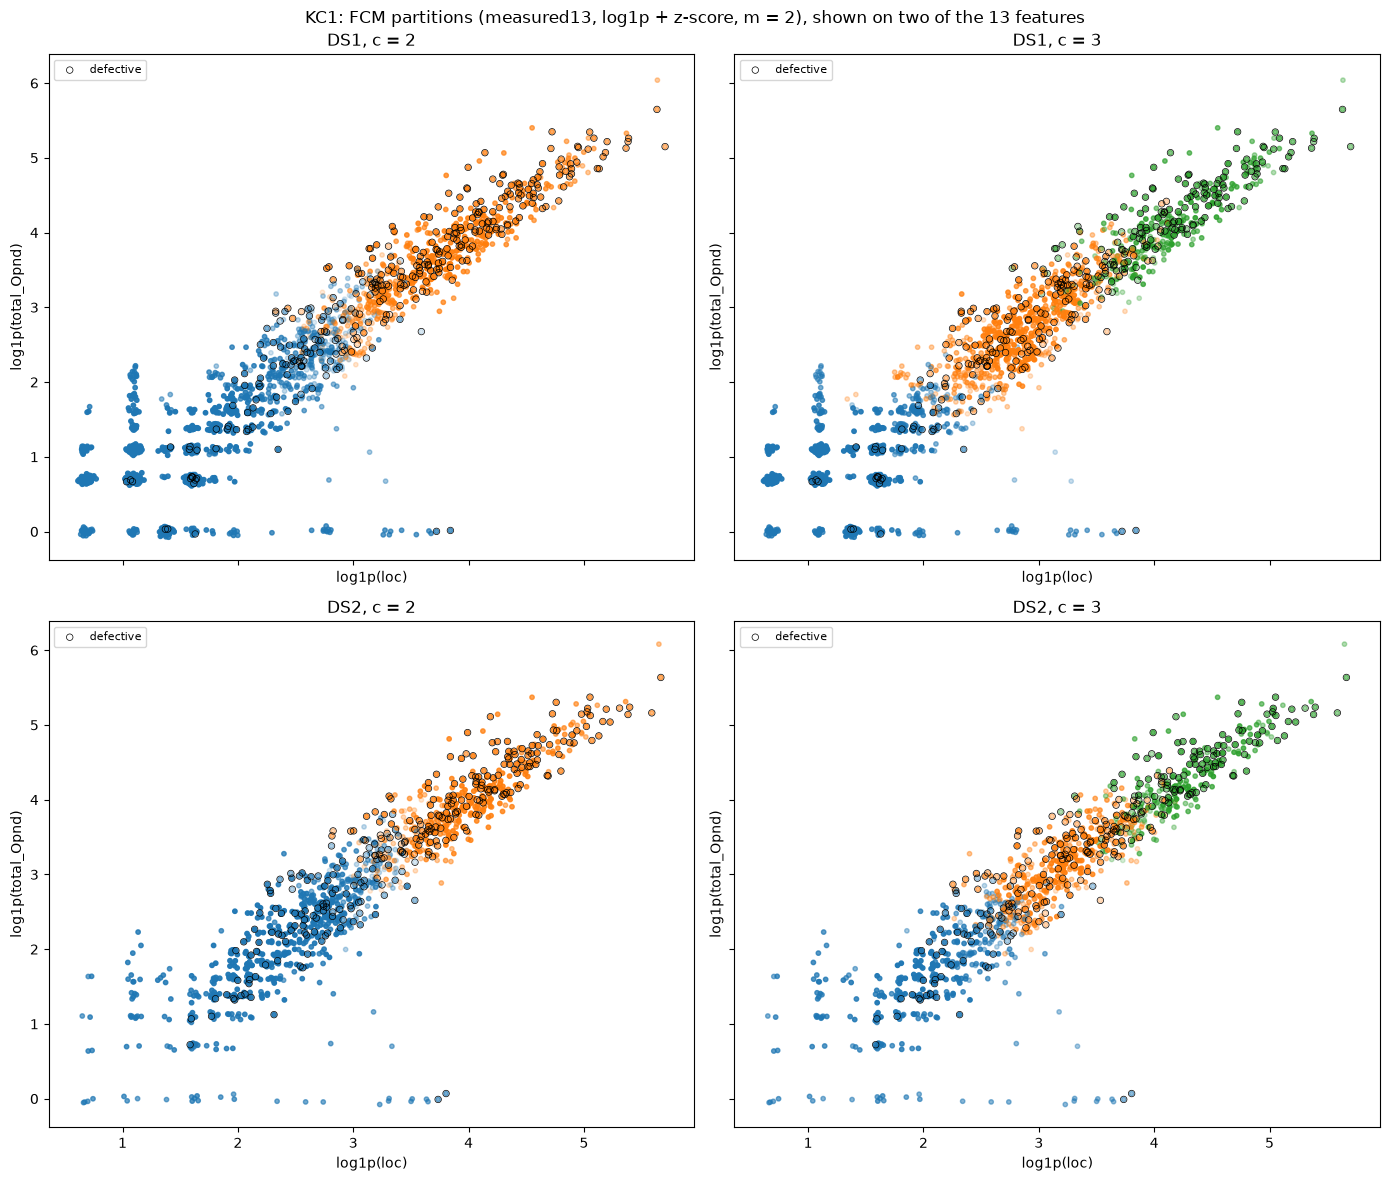

In [35]:
rng_plot = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 2, figsize=(14, 12), sharex=True, sharey=True)
for row, ds_name in enumerate(DS):
    d = DS[ds_name]
    xj = np.log1p(d["loc"].to_numpy()) + rng_plot.normal(0, 0.03, len(d))
    yj = np.log1p(d["total_Opnd"].to_numpy()) + rng_plot.normal(0, 0.03, len(d))
    for col, c in enumerate(PART_C):
        ax = axes[row, col]
        P = parts[(ds_name, "measured13", "log1p_zscore", 2.0, c)]
        colors = plt.cm.tab10(P["labels"])
        colors[:, 3] = 0.15 + 0.85 * (P["maxu"] - P["maxu"].min()) / (P["maxu"].max() - P["maxu"].min())
        ax.scatter(xj, yj, c=colors, s=10)
        dfct = Y[ds_name]
        ax.scatter(xj[dfct], yj[dfct], facecolors="none", edgecolors="black", s=22, linewidths=0.5, label="defective")
        ax.set_title(f"{ds_name}, c = {c}")
        ax.set_xlabel("log1p(loc)")
        ax.set_ylabel("log1p(total_Opnd)")
        ax.legend(loc="upper left", fontsize=8)
fig.suptitle("KC1: FCM partitions (measured13, log1p + z-score, m = 2), shown on two of the 13 features")
fig.tight_layout()
fig.savefig(FIG_DIR / "kc1_partitions_m2.png", dpi=200)
plt.show()

## Step 8: Is there cluster structure, or a continuum? Stability and atypical modules

Main configuration: `measured13`, m = 2, c = 2 and 3, both versions (DS1, DS2) and both variants.

- 8a: distribution of the modules along the first principal component (the "size" direction, 77 % of the variance,
  Step 4e), with the FCM cluster boundaries; number of modes of a kernel density estimate; FCM membership along PC1
- 8b: stability under resampling (10 subsamples of 70 %, whole pipeline refitted), as for the NASA data
- 8c: possibilistic c-means (PCM) started from FCM: modules atypical of both clusters

### 8a: Distribution along PC1

PC1 of the log1p + z-score `measured13` data of each version (eigenvector of the correlation matrix; sign chosen so
that `loc` has a positive loading). Histograms are stacked by hard FCM cluster (z-score, m = 2); clusters can overlap on PC1 because FCM used all 13 features.
Modes are counted on a Gaussian kernel density estimate (scipy `gaussian_kde`, Scott's bandwidth and half of it):
a rough check, not a formal unimodality test.

DS1: PC1 explains 74.5%; loadings: {'loc': np.float64(0.3), 'v(g)': np.float64(0.3), 'ev(g)': np.float64(0.23), 'iv(g)': np.float64(0.3), 'lOCode': np.float64(0.3), 'lOComment': np.float64(0.22), 'lOBlank': np.float64(0.28), 'locCodeAndComment': np.float64(0.11), 'uniq_Op': np.float64(0.28), 'uniq_Opnd': np.float64(0.3), 'total_Op': np.float64(0.31), 'total_Opnd': np.float64(0.31), 'branchCount': np.float64(0.3)}
DS2: PC1 explains 72.6%; loadings: {'loc': np.float64(0.31), 'v(g)': np.float64(0.3), 'ev(g)': np.float64(0.23), 'iv(g)': np.float64(0.3), 'lOCode': np.float64(0.31), 'lOComment': np.float64(0.2), 'lOBlank': np.float64(0.27), 'locCodeAndComment': np.float64(0.1), 'uniq_Op': np.float64(0.28), 'uniq_Opnd': np.float64(0.3), 'total_Op': np.float64(0.31), 'total_Opnd': np.float64(0.31), 'branchCount': np.float64(0.3)}
DS1: KDE bandwidth x1.0: 1 mode(s) at PC1 = [-2.65]
DS1: KDE bandwidth x0.5: 8 mode(s) at PC1 = [-2.76, -0.57, 0.38, 1.78, 3.31, 5.82, 8.59, 10.38]
DS2: KDE bandwidth

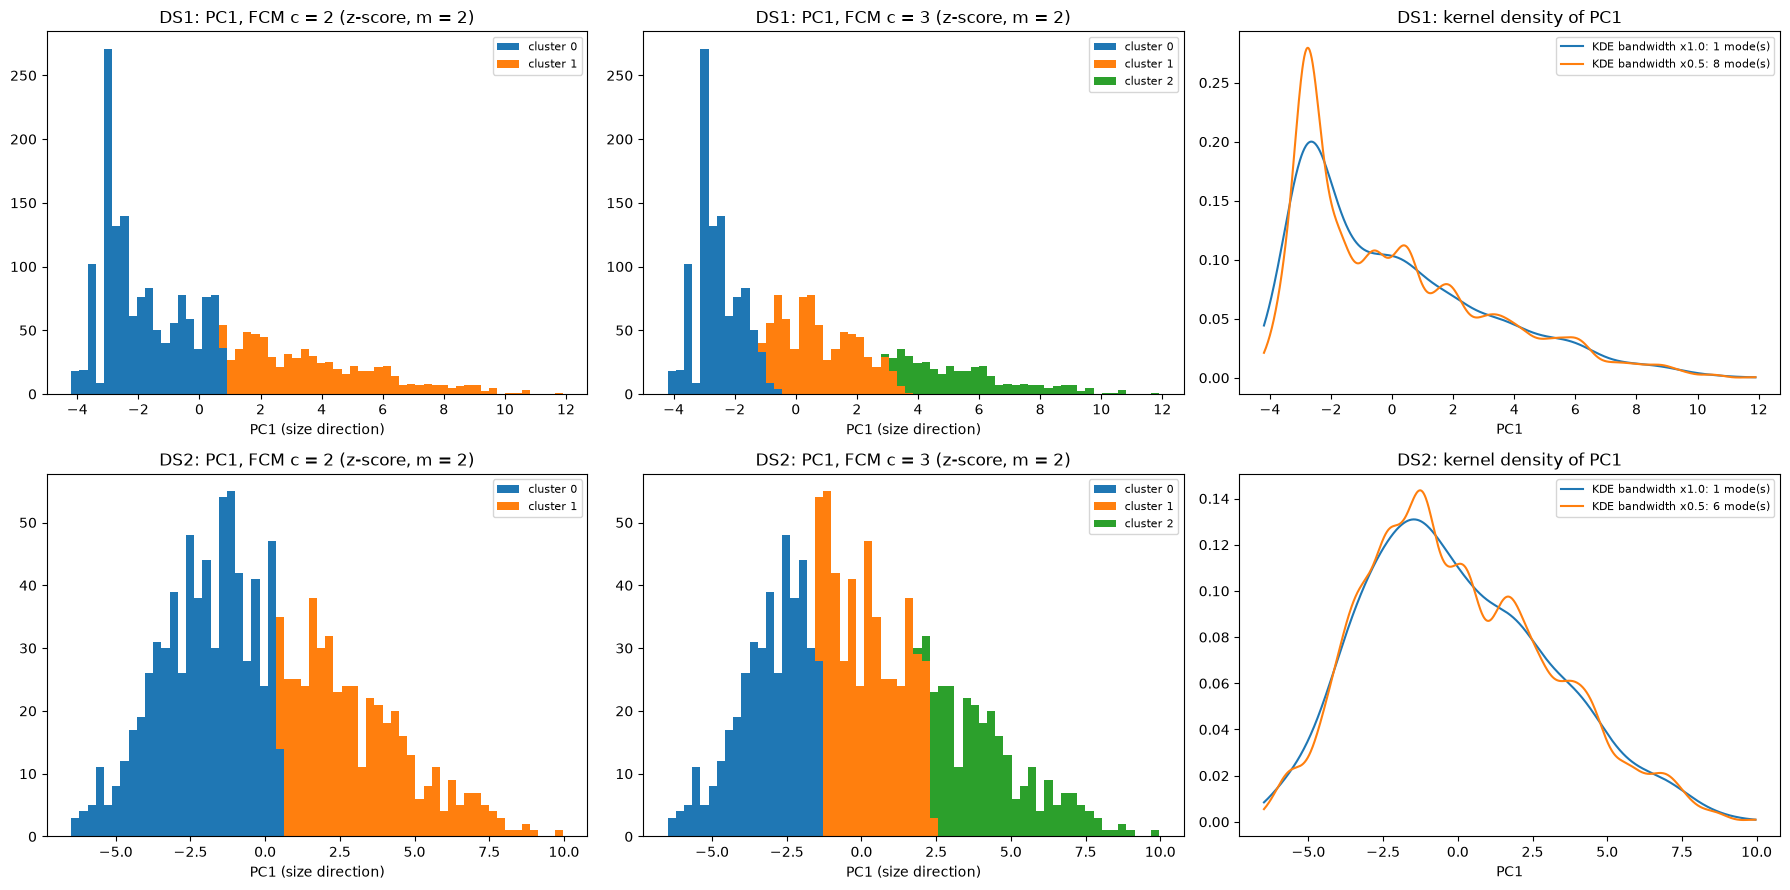

In [36]:
from scipy.stats import gaussian_kde

V_MAIN, M_MAIN = "log1p_zscore", 2.0
pc1 = {}
for ds_name in DS:
    A = data[(ds_name, "measured13", V_MAIN)]
    w, vecs = np.linalg.eigh(np.corrcoef(A, rowvar=False))
    v1 = vecs[:, -1] * np.sign(vecs[FSETS["measured13"].index("loc"), -1])
    pc1[ds_name] = A @ v1
    print(f"{ds_name}: PC1 explains {w[-1] / w.sum():.1%}; loadings:",
          dict(zip(FSETS["measured13"], np.round(v1, 2))))

def n_modes(x, bw_factor):
    kde = gaussian_kde(x)
    kde.set_bandwidth(kde.factor * bw_factor)
    grid_x = np.linspace(x.min(), x.max(), 1000)
    dens = kde(grid_x)
    peaks = np.where((dens[1:-1] > dens[:-2]) & (dens[1:-1] > dens[2:]))[0] + 1
    return len(peaks), grid_x, dens, grid_x[peaks]

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for r, ds_name in enumerate(DS):
    x = pc1[ds_name]
    for col, c in enumerate(PART_C):
        ax = axes[r, col]
        labels = parts[(ds_name, "measured13", V_MAIN, M_MAIN, c)]["labels"]
        bins = np.histogram_bin_edges(x, bins=60)
        ax.hist([x[labels == k] for k in range(c)], bins=bins, stacked=True,
                color=[plt.cm.tab10(k) for k in range(c)], label=[f"cluster {k}" for k in range(c)])
        ax.set_title(f"{ds_name}: PC1, FCM c = {c} (z-score, m = 2)")
        ax.set_xlabel("PC1 (size direction)")
        ax.legend(fontsize=8)
    ax = axes[r, 2]
    for bw in (1.0, 0.5):
        k_modes, gx, dens, peaks = n_modes(x, bw)
        ax.plot(gx, dens, label=f"KDE bandwidth x{bw}: {k_modes} mode(s)")
        print(f"{ds_name}: KDE bandwidth x{bw}: {k_modes} mode(s) at PC1 = {np.round(peaks, 2).tolist()}")
    ax.set_title(f"{ds_name}: kernel density of PC1")
    ax.set_xlabel("PC1")
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "kc1_pc1_distribution.png", dpi=200)
plt.show()

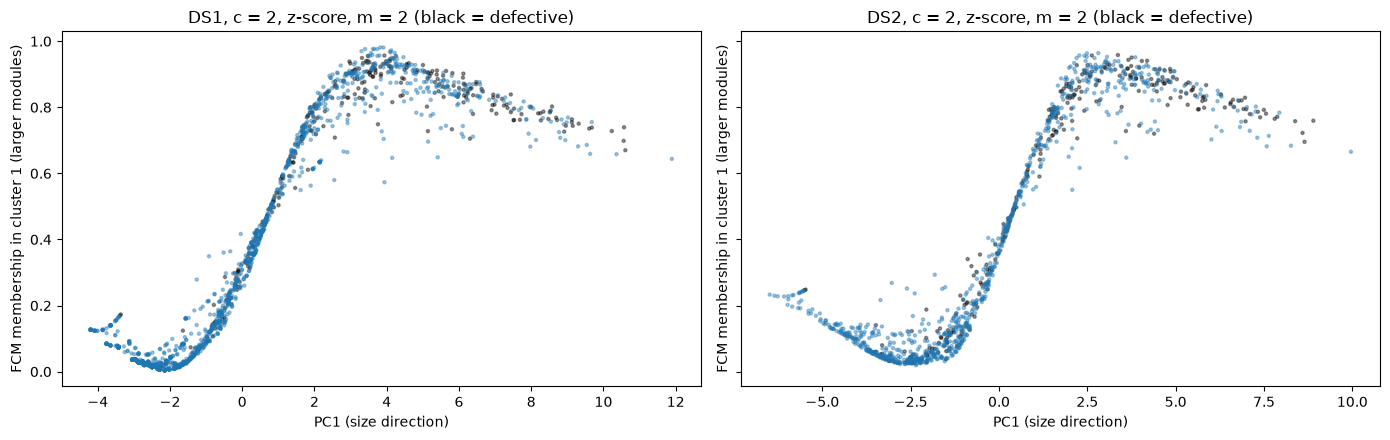

DS1: modules with max membership < 0.6 (c = 2): 163 of 2096
DS2: modules with max membership < 0.6 (c = 2): 100 of 1163


In [37]:
# FCM membership in the "large" cluster along PC1: a sharp step would mean two separated groups,
# a gradual S-curve means the partition is a soft cut through a continuum
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, ds_name in zip(axes, DS):
    U = parts[(ds_name, "measured13", V_MAIN, M_MAIN, 2)]["U"]
    ax.scatter(pc1[ds_name], U[1], s=5, alpha=0.4, c=np.where(Y[ds_name], "black", "tab:blue"))
    ax.set_xlabel("PC1 (size direction)")
    ax.set_ylabel("FCM membership in cluster 1 (larger modules)")
    ax.set_title(f"{ds_name}, c = 2, z-score, m = 2 (black = defective)")
fig.tight_layout()
fig.savefig(FIG_DIR / "kc1_membership_along_pc1.png", dpi=200)
plt.show()

for ds_name in DS:
    U = parts[(ds_name, "measured13", V_MAIN, M_MAIN, 2)]["U"]
    print(f"{ds_name}: modules with max membership < 0.6 (c = 2): {int((U.max(axis=0) < 0.6).sum())} of {U.shape[1]}")

### 8b: Stability under resampling

`N_SUB` = 10 random subsamples of 70 % of the modules (seeds `SEED + r`). On each subsample the whole pipeline is
refitted (log1p, then scaling fitted on the subsample only, FCM with 10 starts), and its partition is compared (ARI)
with the full-data partition restricted to the same modules. Prototypes are reported in original units
(clusters ordered by prototype `loc`). `measured13`, m = 2, c = 2 and 3, both versions and variants.

In [38]:
N_SUB, FRAC = 10, 0.7
cols13 = FSETS["measured13"]
stab_rows = []
for ds_name in DS:
    L = np.log1p(DS[ds_name][cols13].to_numpy(dtype=float))
    for r in range(N_SUB):
        rng = np.random.default_rng(SEED + r)
        idx = np.sort(rng.choice(len(L), size=int(FRAC * len(L)), replace=False))
        Ls = L[idx]
        for v_name, scale in SCALERS.items():
            A_sub = scale(Ls)
            for c in PART_C:
                best, info = fcm.fcm_multistart(A_sub, c, m=M_MAIN, n_init=N_INIT, seed=SEED, eps=FCM_EPS, max_iter=FCM_MAX_ITER)
                if v_name == "log1p_zscore":
                    Vl = best.V * Ls.std(axis=0) + Ls.mean(axis=0)
                else:
                    Vl = best.V * np.ptp(Ls, axis=0) + Ls.min(axis=0)
                order = np.argsort(Vl[:, cols13.index("loc")])
                proto = np.expm1(Vl[order])
                stab_rows.append({
                    "version": ds_name, "subsample": r, "variant": v_name, "c": c,
                    "ARI vs full data": adjusted_rand_score(parts[(ds_name, "measured13", v_name, M_MAIN, c)]["labels"][idx], best.labels),
                    "sizes": np.bincount(best.U[order].argmax(axis=0), minlength=c).tolist(),
                    **{f"proto{k}_loc": proto[k, cols13.index("loc")] for k in range(c)},
                    **{f"proto{k}_total_Opnd": proto[k, cols13.index("total_Opnd")] for k in range(c)},
                })
stab = pd.DataFrame(stab_rows)
stab.to_csv(OUT_DIR / "kc1_stability.csv", index=False)
print(stab.groupby(["version", "variant", "c"])["ARI vs full data"].describe()[["mean", "min", "max"]].round(3))
stab.groupby(["version", "variant", "c"])[[c for c in stab.columns if c.endswith("_loc")]].agg(["min", "max"]).round(1)

                         mean    min    max
version variant      c                     
DS1     log1p_minmax 2  0.954  0.919  0.986
                     3  0.977  0.950  0.991
        log1p_zscore 2  0.981  0.964  1.000
                     3  0.987  0.975  0.996
DS2     log1p_minmax 2  0.978  0.961  0.995
                     3  0.944  0.889  0.980
        log1p_zscore 2  0.985  0.961  1.000
                     3  0.966  0.906  0.989


proto0_loc       proto1_loc       proto2_loc      
                              min   max        min   max        min   max
version variant      c                                                   
DS1     log1p_minmax 2        4.0   4.3       34.4  38.3        NaN   NaN
                     3        2.9   3.1       15.3  16.5       56.1  63.6
        log1p_zscore 2        4.3   4.5       36.2  40.0        NaN   NaN
                     3        3.0   3.2       16.5  17.4       56.3  63.9
DS2     log1p_minmax 2       10.3  11.0       50.6  54.4        NaN   NaN
                     3        7.5   8.1       23.6  25.8       67.1  74.9
        log1p_zscore 2       10.2  10.9       49.3  52.6        NaN   NaN
                     3        7.3   7.9       22.8  24.9       64.1  71.7

### 8c: Possibilistic c-means (PCM) started from FCM

Same recipe as for WDBC and the NASA data (lecture 05a, slides 21-23; Krishnapuram & Keller 1993, 1996):
(1) FCM, (2) eta_i from the FCM result, (3) PCM from the FCM prototypes with eta fixed.
Configuration: `measured13`, c = 2, m = 2, both versions and variants.
Checked first: do the PCM prototypes stay apart (coincident clusters are the known PCM weakness, seen with z-score
on WDBC and on the NASA data)? Then: which modules are atypical of both clusters (largest typicality < 0.5), and is
their defect rate different?

In [39]:
C_PCM = 2
pcm_runs, pcm_rows = {}, []
for ds_name in DS:
    for v_name in SCALERS:
        A = data[(ds_name, "measured13", v_name)]
        res_f = grid_runs[(ds_name, "measured13", v_name, M_MAIN, C_PCM)]
        eta = fcm.pcm_eta(A, res_f.U, res_f.V, M_MAIN)
        res_p = fcm.pcm(A, res_f.V, eta, m=M_MAIN, eps=FCM_EPS, max_iter=FCM_MAX_ITER)
        pcm_runs[(ds_name, v_name)] = (res_f, res_p, eta)
        d_f = fcm.prototype_diagnostics(A, res_f)["min_proto_dist"]
        d_p = fcm.prototype_diagnostics(A, res_p)["min_proto_dist"]
        for alg, res in (("FCM", res_f), ("PCM", res_p)):
            orig = to_original(ds_name, "measured13", v_name, res.V).sort_values("loc")
            pcm_rows.append({"version": ds_name, "variant": v_name, "algorithm": alg,
                             "iterations": res.n_iter, "converged": res.converged,
                             "prototype distance": round(d_f if alg == "FCM" else d_p, 3),
                             "prototype loc": orig["loc"].round(1).tolist(),
                             "prototype total_Opnd": orig["total_Opnd"].round(1).tolist(),
                             "cluster sizes": np.bincount(res.labels, minlength=C_PCM).tolist()})
        print(f"{ds_name} {v_name}: PCM/FCM prototype distance = {d_p / d_f:.2f}"
              f"{'  -> coincident clusters' if d_p / d_f < 0.25 else ''};"
              f"  ARI FCM vs PCM hard labels = {adjusted_rand_score(res_f.labels, res_p.labels):.3f}")
pcm_summary = pd.DataFrame(pcm_rows)
pcm_summary.to_csv(OUT_DIR / "kc1_pcm_vs_fcm.csv", index=False)
pcm_summary

DS1 log1p_zscore: PCM/FCM prototype distance = 0.12  -> coincident clusters;  ARI FCM vs PCM hard labels = -0.063
DS1 log1p_minmax: PCM/FCM prototype distance = 0.11  -> coincident clusters;  ARI FCM vs PCM hard labels = -0.023
DS2 log1p_zscore: PCM/FCM prototype distance = 0.03  -> coincident clusters;  ARI FCM vs PCM hard labels = 0.000
DS2 log1p_minmax: PCM/FCM prototype distance = 0.04  -> coincident clusters;  ARI FCM vs PCM hard labels = 0.000


,version,variant,algorithm,iterations,converged,prototype distance,prototype loc,prototype total_Opnd,cluster sizes
0,DS1,log1p_zscore,FCM,33,True,5.601,"[4.4, 38.4]","[2.4, 35.9]","[677, 1419]"
1,DS1,log1p_zscore,PCM,27,True,0.674,"[3.4, 4.9]","[1.9, 3.0]","[1790, 306]"
2,DS1,log1p_minmax,FCM,32,True,1.172,"[4.1, 36.6]","[2.2, 34.1]","[765, 1331]"
3,DS1,log1p_minmax,PCM,35,True,0.128,"[3.2, 4.5]","[1.7, 2.7]","[1719, 377]"
4,DS2,log1p_zscore,FCM,28,True,5.082,"[10.5, 50.7]","[7.5, 49.3]","[462, 701]"
5,DS2,log1p_zscore,PCM,35,True,0.167,"[14.9, 15.7]","[12.3, 13.0]","[1163, 0]"
6,DS2,log1p_minmax,FCM,29,True,1.043,"[10.6, 52.1]","[7.6, 50.7]","[712, 451]"
7,DS2,log1p_minmax,PCM,37,True,0.038,"[14.4, 15.2]","[11.7, 12.4]","[0, 1163]"


In [40]:
# Point level, only for runs whose PCM prototypes stayed apart (ratio >= 0.25): otherwise the typicalities measure
# the distance to a single prototype, not atypicality with respect to both clusters.
SHOW_PTS = ["loc", "v(g)", "lOCode", "lOComment", "lOBlank", "uniq_Op", "uniq_Opnd", "total_Op", "total_Opnd", "branchCount"]
pcm_points, atyp_rows = {}, []
for (ds_name, v_name), (res_f, res_p, eta) in pcm_runs.items():
    A = data[(ds_name, "measured13", v_name)]
    ratio = fcm.prototype_diagnostics(A, res_p)["min_proto_dist"] / fcm.prototype_diagnostics(A, res_f)["min_proto_dist"]
    if ratio < 0.25:
        continue
    pts = DS[ds_name][SHOW_PTS + ["defects"]].copy()
    pts["copies"] = DS[ds_name].groupby(FEATURES, sort=False)["defects"].transform("size")
    pts["fcm_max_u"] = res_f.U.max(axis=0)
    pts["pcm_max_t"] = res_p.U.max(axis=0)
    pts["dist_to_nearest_proto"] = np.sqrt(fcm.squared_distances(A, res_p.V).min(axis=0))
    pts.to_csv(OUT_DIR / f"kc1_{ds_name.lower()}_{v_name}_pcm_points.csv", index_label="row")
    pcm_points[(ds_name, v_name)] = pts
    atyp = pts["pcm_max_t"] < 0.5
    atyp_rows.append({"version": ds_name, "variant": v_name, "atypical (t < 0.5)": int(atyp.sum()),
                      "share": round(float(atyp.mean()), 3),
                      "defect rate atypical": round(float(pts.loc[atyp, "defects"].mean()), 3) if atyp.any() else np.nan,
                      "defect rate typical": round(float(pts.loc[~atyp, "defects"].mean()), 3),
                      "atypical with FCM max u >= 0.8": int((atyp & (pts["fcm_max_u"] >= 0.8)).sum()),
                      "corr(dist, FCM max u)": round(float(np.corrcoef(pts["dist_to_nearest_proto"], pts["fcm_max_u"])[0, 1]), 3),
                      "corr(dist, PCM max t)": round(float(np.corrcoef(pts["dist_to_nearest_proto"], pts["pcm_max_t"])[0, 1]), 3)})
display(pd.DataFrame(atyp_rows))
for key_, pts in pcm_points.items():
    print(f"\n{key_}: 15 most atypical modules")
    display(pts.sort_values("pcm_max_t").head(15).round(3))

""


In [41]:
# FCM membership vs PCM typicality on the loc / total_Opnd plane (log1p axes, jitter for display only)
keys = list(pcm_points)
if keys:
    rng_plot = np.random.default_rng(SEED)
    fig, axes = plt.subplots(len(keys), 2, figsize=(14, 5.5 * len(keys)), squeeze=False)
    for r, key_ in enumerate(keys):
        pts = pcm_points[key_]
        xj = np.log1p(pts["loc"].to_numpy()) + rng_plot.normal(0, 0.03, len(pts))
        yj = np.log1p(pts["total_Opnd"].to_numpy()) + rng_plot.normal(0, 0.03, len(pts))
        for j, (col, title) in enumerate([("fcm_max_u", "FCM: largest membership"), ("pcm_max_t", "PCM: largest typicality")]):
            ax = axes[r, j]
            sc = ax.scatter(xj, yj, c=pts[col], cmap="viridis", vmin=0, vmax=1, s=8)
            ax.set_xlabel("log1p(loc)")
            ax.set_ylabel("log1p(total_Opnd)")
            ax.set_title(f"{key_[0]} {key_[1]}: {title}", fontsize=10)
            fig.colorbar(sc, ax=ax)
    fig.tight_layout()
    fig.savefig(FIG_DIR / "kc1_pcm_vs_fcm.png", dpi=200)
    plt.show()
else:
    print("all PCM runs produced coincident clusters: no point-level figure")

all PCM runs produced coincident clusters: no point-level figure
